# Land Type Classification Using Deep Learning and Satellite Imagery

**Final-run candidate — evaluation, persistent checkpoints, and deployment-readiness.**

Three models are trained and evaluated on EuroSAT (27,000 images; 10 classes): **ResNet50 RGB**, **EfficientNet-B0 RGB**, and **ResNet50 multispectral (13 bands)**. The notebook uses a stratified 70/15/15 split (seed 42), validation-selected checkpoints, final held-out test evaluation, interpretability, and reproducible data pipelines.

**For the final run:** use a Google Colab **GPU**; run `Runtime → Restart session and run all` once; authorize Google Drive when prompted; keep all model checkpoints and the deployment manifest saved to the displayed versioned Drive folder. Do not run interactive upload or Gradio demo inside Run All. The previously optional 64×64 ablation has been removed; standard RGB models still resize the original 64×64 EuroSAT images to 224×224.


> **Notebook revision for the final run; training has NOT been rerun after these edits.**
>
> Source: executed `Land_Type_Classification_Reproducibility_Fixes(3).ipynb`, whose saved outputs reported **ResNet50 RGB 97.90%**, **EfficientNet-B0 RGB 97.04%**, and **ResNet50 13-band 98.74%** on 4,050 test images each. These are **reference values from the source run**, not results of this edited notebook.
>
> Improvements in this version: real measured RGB training duration (rather than hardcoded old epochs), stronger split/evaluation audits, independent train/val/test MS DataLoader generators, automatic versioned Google Drive checkpoint backups and integrity checks, a standalone checkpoint-based inference contract for all three models, deployment smoke tests, and a final machine-readable result/manifest export.
>
> **Before final submission:** execute all code cells from a fresh Colab GPU session, verify there are no errors, check sequential execution counts, and **save the executed notebook**. The full MS download and training require substantial Colab time/disk space and cannot be validated by syntax checks alone.


## 1. Project Overview

EuroSAT contains 27,000 RGB satellite images across 10 land-cover classes. The target split is 70% training, 15% validation, and 15% testing. ResNet50 expects 224 × 224 inputs, so the original 64 × 64 images will be resized.

In [1]:
PROJECT_NAME = "Land Type Classification Using Deep Learning and Satellite Imagery"
DATASET_NAME = "EuroSAT"
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print(PROJECT_NAME)
print(f"Dataset: {DATASET_NAME} | Classes: {NUM_CLASSES} | Input: {IMAGE_SIZE}x{IMAGE_SIZE} RGB")
print(f"Split: 70% train / 15% validation / 15% test | Batch size: {BATCH_SIZE}")

Land Type Classification Using Deep Learning and Satellite Imagery
Dataset: EuroSAT | Classes: 10 | Input: 224x224 RGB
Split: 70% train / 15% validation / 15% test | Batch size: 32


## 2. Environment Setup

Import the project dependencies, set reproducibility controls, and select the available GPU when Colab provides one. Colab already includes the required packages in its standard PyTorch runtime.

In [2]:
import copy
import random
import sys
import time
from pathlib import Path
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import EuroSAT

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/eurosat_data") if Path("/content").exists() else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; training will use CPU and take longer.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


## Persistent Run Artifacts — **authorize Google Drive before training**

Every final run uses a **new timestamped folder** to prevent accidentally overwriting the checkpoints from an older run. The same verified file is saved locally and copied to `MyDrive/Land_Type_Classification/checkpoints/<run_id>/` immediately when each model finishes. Any backup/integrity failure **raises an error**, rather than printing a misleading success message.

> Colab asks you to authorize Drive once at the beginning. The `.pth` checkpoints and a final JSON manifest/CSV are persistent; the **notebook itself must also be saved** via `File → Save a copy in Drive` or by downloading it at the end. A GPU is strongly recommended for the full retraining run.

In [3]:
import hashlib
import json
import os
import shutil
from datetime import datetime, timezone

RUN_ID = datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S_UTC")
LOCAL_CHECKPOINT_DIR = Path.cwd() / "checkpoints" / RUN_ID
LOCAL_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RUNNING_ON_COLAB = Path("/content").is_dir()
if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PERSISTENT_CHECKPOINT_DIR = (
        Path("/content/drive/MyDrive/Land_Type_Classification/checkpoints") / RUN_ID
    )
else:
    # Outside Colab, use a permanent local folder; backups still use verification.
    PERSISTENT_CHECKPOINT_DIR = Path.cwd() / "saved_checkpoints" / RUN_ID
PERSISTENT_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Fail early if Google Drive is disconnected or not writable.
probe = PERSISTENT_CHECKPOINT_DIR / ".write_test"
probe.write_text("ok", encoding="utf-8")
assert probe.read_text(encoding="utf-8") == "ok"
probe.unlink()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as input_file:
        for chunk in iter(lambda: input_file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def save_verified_checkpoint(payload, local_path):
    """Atomically save, reload-check and persist a PyTorch weights-only checkpoint."""
    local_path = Path(local_path)
    local_path.parent.mkdir(parents=True, exist_ok=True)
    if len(payload.get("class_names", [])) != NUM_CLASSES:
        raise ValueError("Checkpoint must retain the 10 ordered class names.")
    if not {"model_state_dict", "architecture", "input_channels", "image_size"} <= set(payload):
        raise ValueError("Checkpoint is missing required inference metadata.")
    if int(payload["input_channels"]) not in (3, 13):
        raise ValueError("Invalid number of checkpoint input channels.")

    temporary_path = local_path.with_name(local_path.name + ".tmp")
    try:
        torch.save(payload, temporary_path)
        reloaded = torch.load(temporary_path, map_location="cpu", weights_only=True)
        assert reloaded["class_names"] == list(payload["class_names"])
        assert reloaded["architecture"] == payload["architecture"]
        assert "model_state_dict" in reloaded and len(reloaded["model_state_dict"]) > 0
        os.replace(temporary_path, local_path)
    finally:
        temporary_path.unlink(missing_ok=True)

    persistent_path = PERSISTENT_CHECKPOINT_DIR / local_path.name
    persistent_tmp = persistent_path.with_name(persistent_path.name + ".tmp")
    try:
        shutil.copy2(local_path, persistent_tmp)
        if sha256_file(local_path) != sha256_file(persistent_tmp):
            raise IOError(f"SHA256 verification FAILED: {persistent_tmp}")
        os.replace(persistent_tmp, persistent_path)
    finally:
        persistent_tmp.unlink(missing_ok=True)

    verified = torch.load(persistent_path, map_location="cpu", weights_only=True)
    assert verified["architecture"] == payload["architecture"]
    assert sha256_file(local_path) == sha256_file(persistent_path)
    print(f"SAVED & VERIFIED locally: {local_path}")
    print(f"SAVED & VERIFIED persistently: {persistent_path}")
    return persistent_path

print("Run ID:", RUN_ID)
print("Local checkpoints:", LOCAL_CHECKPOINT_DIR)
print("Persistent checkpoints:", PERSISTENT_CHECKPOINT_DIR)
if RUNNING_ON_COLAB and device.type != "cuda":
    print("WARNING: CPU runtime selected; the full three-model training run will be much slower.")

Mounted at /content/drive
Run ID: run_20261121_003103_UTC
Local checkpoints: /content/checkpoints/run_20261121_003103_UTC
Persistent checkpoints: /content/drive/MyDrive/Land_Type_Classification/checkpoints/run_20261121_003103_UTC


## 3. Dataset Collection

Load EuroSAT through torchvision. The download is performed only if the dataset is not already present in the selected data directory.

In [4]:
dataset = EuroSAT(root=str(DATA_DIR), download=True)
class_names = dataset.classes
targets = np.asarray(dataset.targets, dtype=np.int64)

print("Dataset downloaded and loaded.")
print("Total images:", len(dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

100%|██████████| 94.3M/94.3M [00:01<00:00, 84.7MB/s]


Dataset downloaded and loaded.
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 4. Exploratory Data Analysis (EDA)

Check the number of images in each class and visualize the distribution. EuroSAT is close to balanced, with modest differences in a few class counts.

                  Class  Number of Images
0            AnnualCrop              3000
1                Forest              3000
2  HerbaceousVegetation              3000
3               Highway              2500
4            Industrial              2500
5               Pasture              2000
6         PermanentCrop              2500
7           Residential              3000
8                 River              2500
9               SeaLake              3000


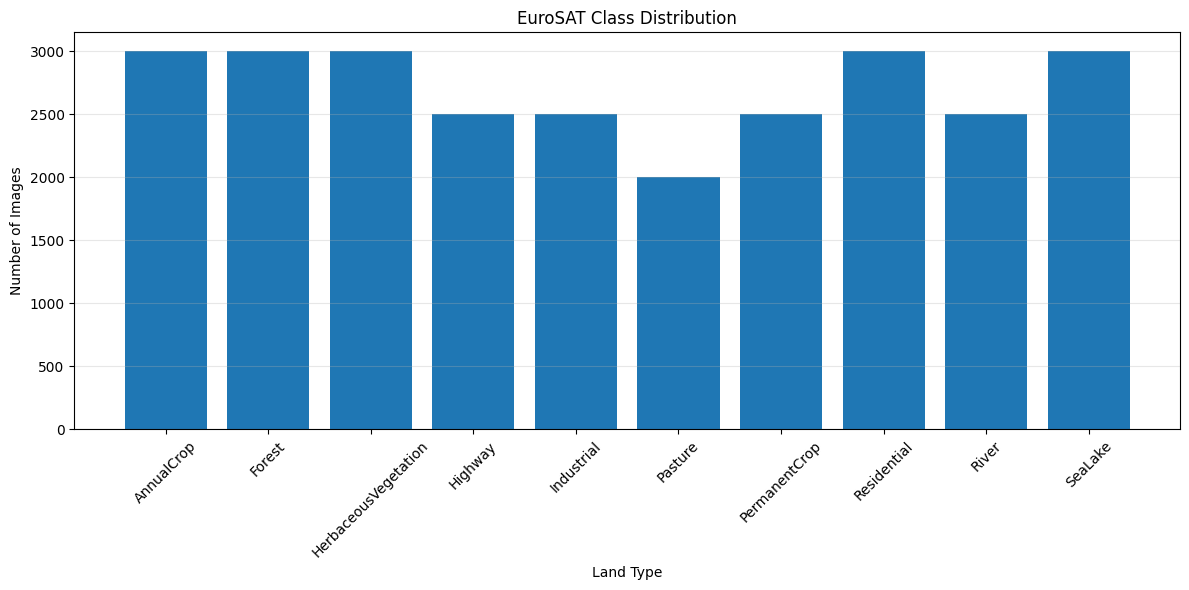

In [5]:
class_counts = pd.Series(dataset.targets).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": dataset.classes,
    "Number of Images": class_counts.values
})

print(class_distribution)

plt.figure(figsize=(12, 6))
plt.bar(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)
plt.title("EuroSAT Class Distribution")
plt.xlabel("Land Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Image Understanding

Display one representative image from each class. The examples remain in their original 64 × 64 RGB form at this stage.

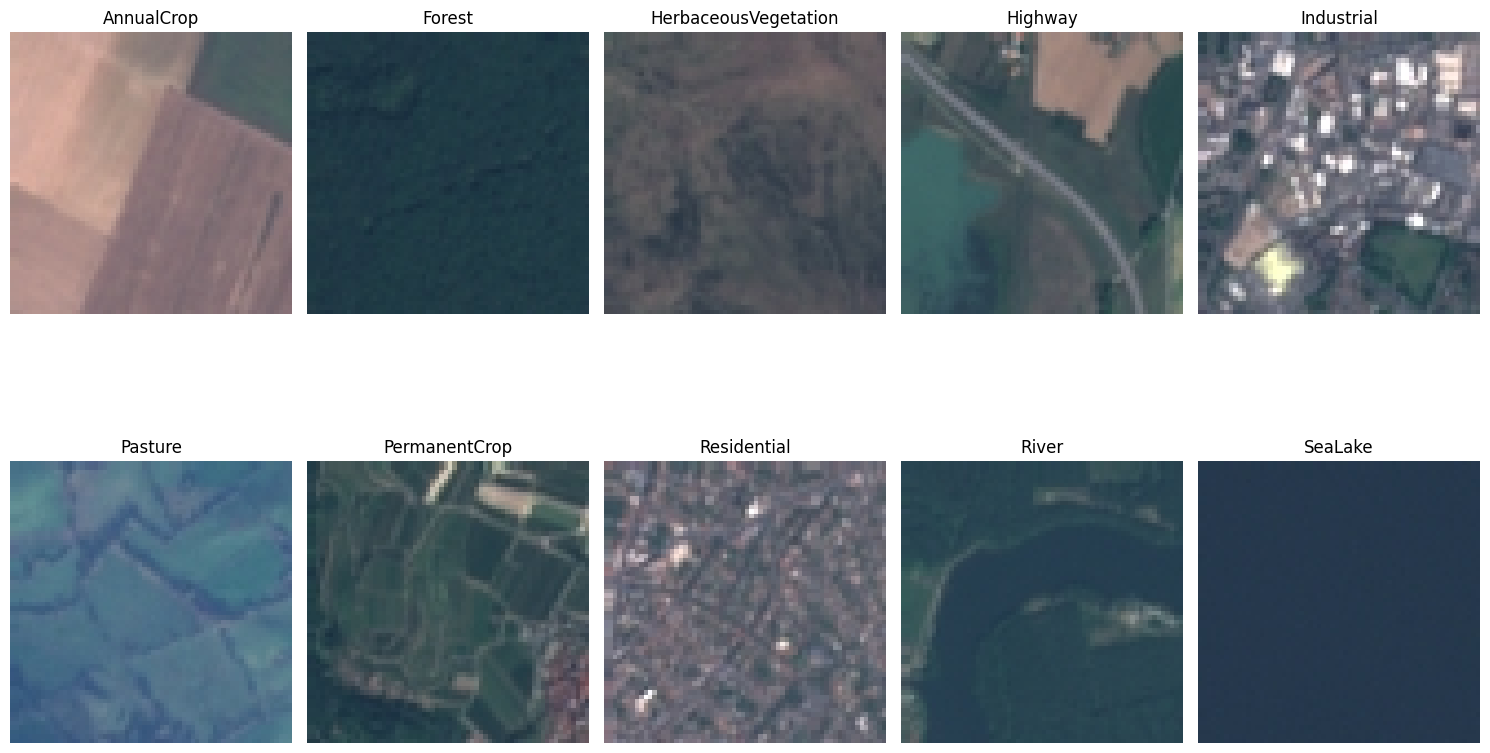

In [6]:
class_images = defaultdict(list)
for index, label in enumerate(targets):
    class_images[int(label)].append(index)

plt.figure(figsize=(15, 10))
for class_id, class_name in enumerate(class_names):
    image_index = random.choice(class_images[class_id])
    image, _ = dataset[image_index]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Inspect a raw sample before defining model transforms. EuroSAT images are RGB PIL images with 8-bit pixel values; resizing and normalization are applied in the transformation stage.

In [7]:
sample_image, sample_label = dataset[0]
image_array = np.asarray(sample_image)

print("Image class:", class_names[sample_label])
print("Image mode:", sample_image.mode)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Pixel range:", int(image_array.min()), "to", int(image_array.max()))

assert sample_image.mode == "RGB", "Expected an RGB image."
assert image_array.shape == (64, 64, 3), "Expected a 64x64 RGB EuroSAT image."

Image class: AnnualCrop
Image mode: RGB
Image shape: (64, 64, 3)
Image data type: uint8
Pixel range: 82 to 204


## 7. Dataset Splitting

Create reproducible stratified splits so each subset keeps approximately the same class distribution. The test set is held out until the final evaluation.

In [8]:
all_indices = np.arange(len(targets))

test_count = int(round(0.15 * len(all_indices)))
val_count = int(round(0.15 * len(all_indices)))

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=test_count,
    random_state=SEED,
    stratify=targets,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_count,
    random_state=SEED,
    stratify=targets[train_val_indices],
)

split_summary = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(targets[train_indices], minlength=NUM_CLASSES),
    "Validation": np.bincount(targets[val_indices], minlength=NUM_CLASSES),
    "Test": np.bincount(targets[test_indices], minlength=NUM_CLASSES),
})

print(f"Training images:   {len(train_indices):,}")
print(f"Validation images: {len(val_indices):,}")
print(f"Testing images:    {len(test_indices):,}")
display(split_summary)

assert (len(train_indices), len(val_indices), len(test_indices)) == (18_900, 4_050, 4_050)
assert len(set(map(int, train_indices))) == len(train_indices)
assert len(set(map(int, val_indices))) == len(val_indices)
assert len(set(map(int, test_indices))) == len(test_indices)
assert not (set(train_indices) & set(val_indices))
assert not (set(train_indices) & set(test_indices))
assert not (set(val_indices) & set(test_indices))
assert len(set(train_indices) | set(val_indices) | set(test_indices)) == len(dataset)
print("PASSED: no RGB image-index overlap across train/validation/test.")


Training images:   18,900
Validation images: 4,050
Testing images:    4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


PASSED: no RGB image-index overlap across train/validation/test.


## 8. Image Transformations

Resize each image to 224 × 224 and apply ImageNet normalization expected by pretrained ResNet50 weights. Random flips and rotation are used only for training; validation and test transforms are deterministic.

In [9]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training and evaluation transforms are ready.")

Training and evaluation transforms are ready.


### Input-resolution limitation: EuroSAT 64×64 → 224×224

The EuroSAT RGB images are **64×64 pixels**. Both the training and evaluation transforms above upscale each image to **224×224 pixels** to use the established ImageNet-pretrained model pipeline. Interpolation creates more pixel samples but **does not recover or add real spatial detail**. Consequently, higher input dimensions must not be described as higher native satellite resolution. This limitation belongs in the final README, methodology, and project report.

The native 64×64 ablation was deliberately removed from the final pipeline to avoid retraining an unused model; 224×224 remains the predefined input for the RGB models.


## 9. Dataset Preparation

Create separate dataset views so random augmentation is applied to training examples only. Each view uses the same underlying EuroSAT file ordering as the stratified indices.

In [10]:
train_data = EuroSAT(root=str(DATA_DIR), download=False, transform=train_transform)
eval_data = EuroSAT(root=str(DATA_DIR), download=False, transform=eval_transform)

train_set = Subset(train_data, train_indices.tolist())
val_set = Subset(eval_data, val_indices.tolist())
test_set = Subset(eval_data, test_indices.tolist())

assert train_data.classes == class_names
assert eval_data.classes == class_names
print("Prepared dataset sizes:", len(train_set), len(val_set), len(test_set))

Prepared dataset sizes: 18900 4050 4050


## 10. DataLoader Creation

Load batches of 32 images. Pinned memory is enabled on GPU systems, while a small worker count keeps Colab memory use manageable.

In [11]:
NUM_WORKERS = 2 if device.type == "cuda" else 0

# Match the worker-seeding strategy used by the multispectral DataLoaders.
# This function must be defined here: seed_ms_worker is defined much later.
def seed_rgb_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
    "worker_init_fn": seed_rgb_worker,
}

# Separate deterministic generators prevent evaluation iterators from changing
# the subsequent training shuffle order. Train generator uses the requested SEED.
rgb_train_generator = torch.Generator().manual_seed(SEED)
rgb_val_generator = torch.Generator().manual_seed(SEED + 1)
rgb_test_generator = torch.Generator().manual_seed(SEED + 2)

train_loader = DataLoader(
    train_set, shuffle=True, generator=rgb_train_generator, **loader_settings
)
val_loader = DataLoader(
    val_set, shuffle=False, generator=rgb_val_generator, **loader_settings
)
test_loader = DataLoader(
    test_set, shuffle=False, generator=rgb_test_generator, **loader_settings
)

images_batch, labels_batch = next(iter(train_loader))
print("Image batch shape:", tuple(images_batch.shape))
print("Label batch shape:", tuple(labels_batch.shape))
print("Batch size:", BATCH_SIZE)
print(f"Reproducible RGB loaders: seed={SEED}; worker_init_fn=seed_rgb_worker")
del images_batch, labels_batch


Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)
Batch size: 32
Reproducible RGB loaders: seed=42; worker_init_fn=seed_rgb_worker


## 11. Model Building (ResNet50)

Initialize ResNet50 with ImageNet pretrained weights and replace its final fully connected layer with a 10-class classifier. The first run may download the pretrained weights.

In [12]:
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

print("Architecture: ResNet50")
print("Output classes:", model.fc.out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 181MB/s]


Architecture: ResNet50
Output classes: 10
Device: cuda


## 12. Transfer Learning Configuration

Freeze the earlier feature extractor and fine-tune the final ResNet block (`layer4`) together with the new classifier. This reduces trainable parameters and GPU memory use while adapting high-level features to EuroSAT.

In [13]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")

Trainable parameters: 14,985,226 / 23,528,522


## 13. Loss Function and Optimizer

Use multiclass cross-entropy and Adam. Only parameters enabled for fine-tuning are passed to the optimizer.

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (parameter for parameter in model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 14. Model Training

Define reusable epoch functions. Training loss and accuracy are averaged over examples, and the frozen backbone's BatchNorm layers keep their pretrained running statistics.

In [15]:
def run_epoch(loader, training=False):
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_count

    return total_loss / total, correct / total

print("Training and validation epoch functions are ready.")

Training and validation epoch functions are ready.


## 15. Validation and Performance Monitoring

This is the training cell. It runs one training and one validation pass per epoch, tracks loss and accuracy, and retains the weights with the lowest validation loss. Execute it manually when ready; no training is started by the setup cells.

Epoch 01/15 | train loss 0.3203, accuracy 0.9121 | val loss 0.0970, accuracy 0.9704 | 93.1s
Epoch 02/15 | train loss 0.1010, accuracy 0.9679 | val loss 0.0673, accuracy 0.9775 | 93.3s
Epoch 03/15 | train loss 0.0654, accuracy 0.9806 | val loss 0.0581, accuracy 0.9802 | 93.5s
Epoch 04/15 | train loss 0.0538, accuracy 0.9820 | val loss 0.0532, accuracy 0.9825 | 93.9s
Epoch 05/15 | train loss 0.0413, accuracy 0.9859 | val loss 0.0621, accuracy 0.9810 | 93.3s
Epoch 06/15 | train loss 0.0335, accuracy 0.9900 | val loss 0.0662, accuracy 0.9788 | 93.2s
Epoch 07/15 | train loss 0.0255, accuracy 0.9913 | val loss 0.0655, accuracy 0.9795 | 93.6s
Epoch 08/15 | train loss 0.0275, accuracy 0.9912 | val loss 0.0663, accuracy 0.9805 | 92.7s
Early stopping: validation loss did not improve for 4 epochs.
Best epoch: 4 | best validation loss: 0.0532


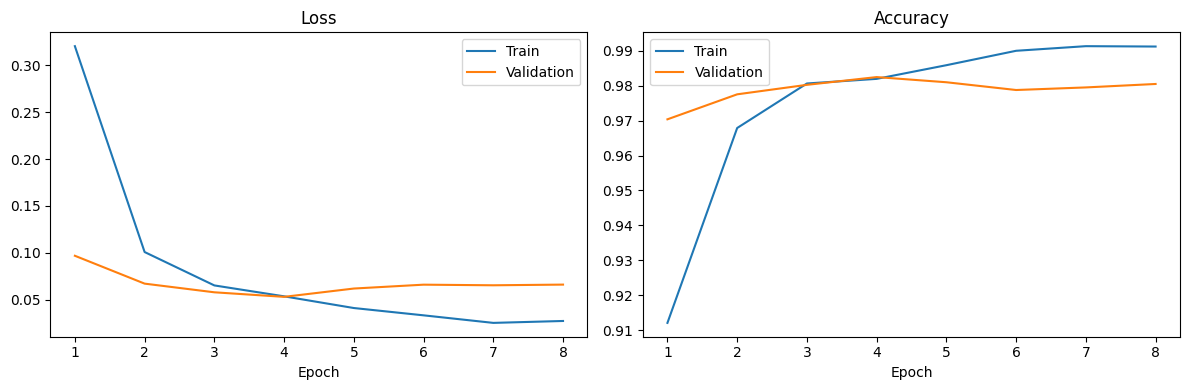

In [16]:
NUM_EPOCHS = 15
RGB_TRAINING_START = time.perf_counter()
RGB_EPOCH_SECONDS = []
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - epoch_start
    RGB_EPOCH_SECONDS.append(float(elapsed))
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{elapsed:.1f}s"
    )
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

RGB_TRAINING_SECONDS = time.perf_counter() - RGB_TRAINING_START
if best_model_state is None:
    raise RuntimeError("Training did not produce a best model checkpoint.")
model.load_state_dict(best_model_state)
print(f"Best epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}")

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 16. Model Evaluation

Restore the best validation checkpoint and evaluate the held-out test set once. Do not use these test results to tune the model.

In [17]:
if best_model_state is None:
    raise RuntimeError("Run the training cell before evaluating the model.")
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test accuracy: {test_accuracy:.4f}")

Test accuracy: 0.9790


## 17. Confusion Matrix

Show how often each true class is predicted as each class. Rows are true labels and columns are predicted labels.

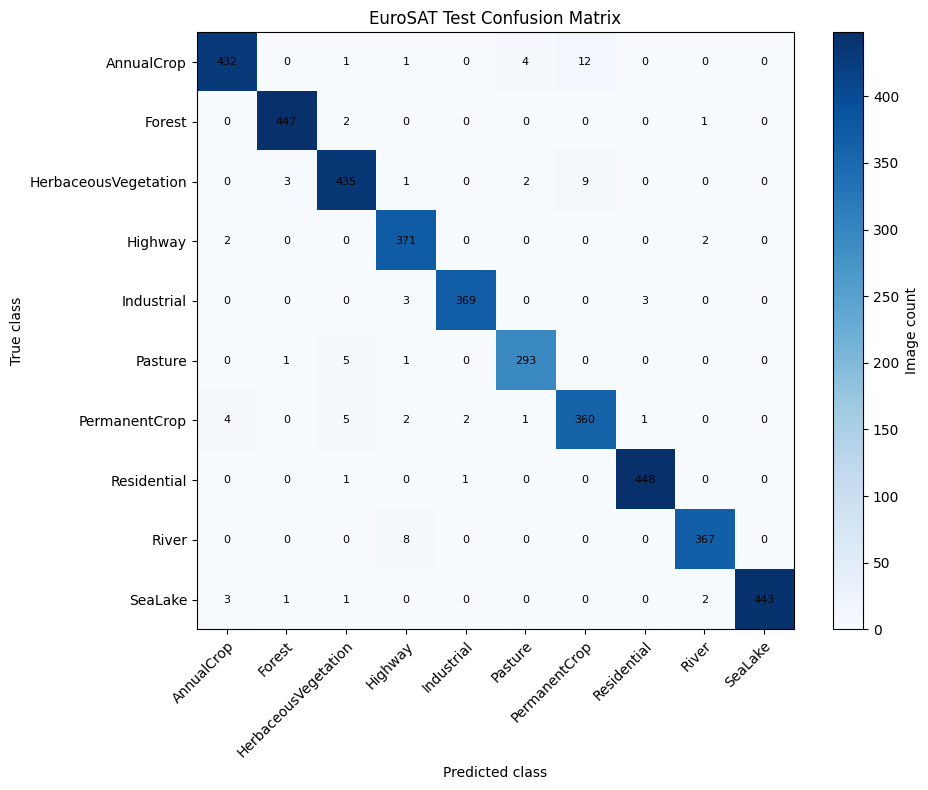

In [18]:
confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 18. Classification Report

Report per-class precision, recall, and F1-score, together with macro and weighted averages.

In [19]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9796    0.9600    0.9697       450
              Forest     0.9889    0.9933    0.9911       450
HerbaceousVegetation     0.9667    0.9667    0.9667       450
             Highway     0.9587    0.9893    0.9738       375
          Industrial     0.9919    0.9840    0.9880       375
             Pasture     0.9767    0.9767    0.9767       300
       PermanentCrop     0.9449    0.9600    0.9524       375
         Residential     0.9912    0.9956    0.9933       450
               River     0.9866    0.9787    0.9826       375
             SeaLake     1.0000    0.9844    0.9922       450

            accuracy                         0.9790      4050
           macro avg     0.9785    0.9789    0.9786      4050
        weighted avg     0.9792    0.9790    0.9790      4050



## 19. Model Saving

Save the best model weights and the class/preprocessing metadata needed to reproduce predictions. In Colab, download this file or save it to mounted Google Drive if you need it after the runtime ends.

In [20]:
MODEL_PATH = LOCAL_CHECKPOINT_DIR / "best_resnet50_eurosat.pth"
checkpoint = {
    "format_version": 2,
    "architecture": "resnet50",
    "input_channels": 3,
    "model_state_dict": {
        key: value.detach().cpu().clone() for key, value in model.state_dict().items()
    },
    "class_names": list(class_names),
    "class_to_idx": {name: i for i, name in enumerate(class_names)},
    "image_size": int(IMAGE_SIZE),
    "imagenet_mean": list(IMAGENET_MEAN),
    "imagenet_std": list(IMAGENET_STD),
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val_loss),
    "training_seconds": float(RGB_TRAINING_SECONDS),
    "dataset": "EuroSAT RGB",
    "seed": int(SEED),
}
RGB_PERSISTENT_CHECKPOINT_PATH = save_verified_checkpoint(checkpoint, MODEL_PATH)
print("ResNet50 actual training seconds:", round(RGB_TRAINING_SECONDS, 1))


SAVED & VERIFIED locally: /content/checkpoints/run_20261121_003103_UTC/best_resnet50_eurosat.pth
SAVED & VERIFIED persistently: /content/drive/MyDrive/Land_Type_Classification/checkpoints/run_20261121_003103_UTC/best_resnet50_eurosat.pth
ResNet50 actual training seconds: 746.5


## 20. Model Loading and Inference

Rebuild the model architecture without downloading weights, load the saved checkpoint, and define a prediction function that applies the same evaluation preprocessing.

In [21]:
loaded_checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
loaded_class_names = loaded_checkpoint["class_names"]
loaded_model = models.resnet50(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, len(loaded_class_names))
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device).eval()

inference_transform = transforms.Compose([
    transforms.Resize((loaded_checkpoint["image_size"], loaded_checkpoint["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=loaded_checkpoint["imagenet_mean"],
        std=loaded_checkpoint["imagenet_std"],
    ),
])

def classify_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(loaded_model(image_tensor), dim=1)[0]
    predicted_index = int(probabilities.argmax().item())
    return loaded_class_names[predicted_index], float(probabilities[predicted_index].item())

print("Loaded model ready for single-image inference.")

Loaded model ready for single-image inference.


## 21. Testing with New Satellite Images

Upload one or more RGB satellite images in Google Colab. The model returns its most likely land-cover class and the associated softmax score.

In [22]:
# Manual upload demo is disabled for Restart & Run All reproducibility.
# Set to True ONLY when you want to select and classify uploaded images in Colab.
RUN_UPLOAD_DEMO = False
if RUN_UPLOAD_DEMO:
    try:
        from google.colab import files
    except ImportError as error:
        raise RuntimeError("Interactive file upload requires Google Colab.") from error
    uploaded_files = files.upload()
    for filename in uploaded_files:
        predicted_class, confidence = classify_image(filename)
        print(f"{filename}: {predicted_class} (score: {confidence:.3f})")
else:
    print("Manual image-upload demo skipped; set RUN_UPLOAD_DEMO=True to run it.")


Manual image-upload demo skipped; set RUN_UPLOAD_DEMO=True to run it.


## 22. Final Conclusion

After running the notebook in order, you will have a reproducible EuroSAT training pipeline, a validation-selected ResNet50 checkpoint, final held-out test metrics, and a function for classifying new satellite images. Record the observed metrics in your project report after the final evaluation.

In [23]:
if "test_accuracy" in globals():
    print(f"Final held-out test accuracy: {test_accuracy:.4f}")
    print("See the classification report and confusion matrix above for detailed results.")
else:
    print("Run the training and evaluation cells to generate final test results.")
print("Inference function: classify_image(image_path)")

Final held-out test accuracy: 0.9790
See the classification report and confusion matrix above for detailed results.
Inference function: classify_image(image_path)


# Phase 2 — RGB Model Comparison and Project Extensions

The preceding cells train and evaluate ResNet50 RGB. This phase trains EfficientNet-B0 RGB on the **same RGB training, validation, and test splits**, compares the resulting metrics, and provides error analysis and Grad-CAM. All summary tables must be calculated from the **current run**, not copied from old notebook outputs.

The final-run pipeline executes its dedicated training cells automatically during `Restart & Run All` and selects checkpoints by validation loss only. The test data are reserved for final reporting and must not be used for additional hyperparameter searches.


## 23. ResNet50 Current-Run Evaluation Audit

Summarize held-out test predictions and measure training duration from the actual ResNet50 run (not from previously saved/rounded epoch logs). A finalized table is assembled again after the multispectral experiment.


In [24]:
baseline_report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

baseline_training_seconds = float(RGB_TRAINING_SECONDS)
baseline_checkpoint_path = Path(MODEL_PATH)
baseline_checkpoint_mb = baseline_checkpoint_path.stat().st_size / (1024 ** 2)
baseline_audit = pd.DataFrame([{
    "Model": "ResNet50 RGB",
    "Test images": len(all_labels),
    "Test accuracy": accuracy_score(all_labels, all_predictions),
    "Macro precision": baseline_report_dict["macro avg"]["precision"],
    "Macro recall": baseline_report_dict["macro avg"]["recall"],
    "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
    "Training time (s)": baseline_training_seconds,
    "Checkpoint size (MiB)": baseline_checkpoint_mb,
}])
display(baseline_audit.round(4))
print("ResNet50 training time measured in this run:", round(baseline_training_seconds, 1), "s")


,Model,Test images,Test accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB)
0,ResNet50 RGB,4050,0.979,0.9785,0.9789,0.9786,746.4859,90.0542


ResNet50 training time measured in this run: 746.5 s


## 24. EfficientNet-B0 Model Building

Load torchvision's ImageNet-pretrained EfficientNet-B0 and replace its last classifier layer with a 10-class head. The first execution may download pretrained weights. The existing 224 × 224 transforms and ImageNet normalization are compatible. [Torchvision model documentation](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html).

In [25]:
torch.manual_seed(SEED + 1)
efficientnet_weights = models.EfficientNet_B0_Weights.DEFAULT
efficientnet_model = models.efficientnet_b0(weights=efficientnet_weights)
efficientnet_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(efficientnet_features, NUM_CLASSES)
efficientnet_model = efficientnet_model.to(device)

print("Architecture: EfficientNet-B0")
print("Output classes:", efficientnet_model.classifier[1].out_features)
print("Device:", device)
print("Pretrained weights:", efficientnet_weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s]


Architecture: EfficientNet-B0
Output classes: 10
Device: cuda
Pretrained weights: EfficientNet_B0_Weights.IMAGENET1K_V1


## 25. EfficientNet Transfer Learning, Loss, and Optimizer

Use the same transfer-learning idea and Adam learning rate as the ResNet50 baseline: freeze earlier features, fine-tune the final feature stage and classifier, and use cross-entropy for the 10 classes.

In [26]:
# Fine-tune both of the final EfficientNet feature stages plus the classifier.
# The original experiment trained only features[-1] and classifier (424,970 params).
for parameter in efficientnet_model.parameters():
    parameter.requires_grad = False
for stage in (efficientnet_model.features[-2], efficientnet_model.features[-1]):
    for parameter in stage.parameters():
        parameter.requires_grad = True
for parameter in efficientnet_model.classifier.parameters():
    parameter.requires_grad = True

efficientnet_trainable = sum(
    parameter.numel() for parameter in efficientnet_model.parameters() if parameter.requires_grad
)
efficientnet_total = sum(parameter.numel() for parameter in efficientnet_model.parameters())
resnet_trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
resnet_total = sum(parameter.numel() for parameter in model.parameters())

eff_criterion = nn.CrossEntropyLoss()
eff_optimizer = torch.optim.Adam(
    (parameter for parameter in efficientnet_model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print(f"EfficientNet trainable: {efficientnet_trainable:,}/{efficientnet_total:,} "
      f"({efficientnet_trainable/efficientnet_total:.2%})")
print(f"ResNet50 trainable: {resnet_trainable:,}/{resnet_total:,} "
      f"({resnet_trainable/resnet_total:.2%})")
print("Unfrozen EfficientNet stages: features[-2], features[-1], classifier")
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")


EfficientNet trainable: 1,142,202/4,020,358 (28.41%)
ResNet50 trainable: 14,985,226/23,528,522 (63.69%)
Unfrozen EfficientNet stages: features[-2], features[-1], classifier
Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 26. EfficientNet Training and Validation Functions

This reusable function mirrors the baseline: it reports example-weighted loss and accuracy, updates weights only during training, and keeps frozen BatchNorm statistics fixed.

In [27]:
def run_model_epoch(model_to_run, loader, loss_function, optimizer=None):
    is_training = optimizer is not None
    model_to_run.train(is_training)

    if is_training:
        for module in model_to_run.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model_to_run(images)
            loss = loss_function(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        count = labels.size(0)
        total_loss += loss.item() * count
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += count

    return total_loss / total_examples, total_correct / total_examples

print("EfficientNet train/validation function is ready.")

EfficientNet train/validation function is ready.


## 27. Train EfficientNet-B0 with Early Stopping

This is the separate EfficientNet training cell. It uses the same batch size, training/validation loaders, epoch limit, patience, loss, optimizer family, and learning rate as the baseline. Run it manually when ready; it does not use the test set.

Epoch 01/15 | train loss 0.5330, accuracy 0.8647 | val loss 0.1853, accuracy 0.9398 | 59.5s
Epoch 02/15 | train loss 0.2008, accuracy 0.9367 | val loss 0.1592, accuracy 0.9430 | 61.7s
Epoch 03/15 | train loss 0.1638, accuracy 0.9474 | val loss 0.1364, accuracy 0.9499 | 61.5s
Epoch 04/15 | train loss 0.1424, accuracy 0.9541 | val loss 0.1183, accuracy 0.9575 | 64.7s
Epoch 05/15 | train loss 0.1207, accuracy 0.9605 | val loss 0.1038, accuracy 0.9615 | 72.6s
Epoch 06/15 | train loss 0.1066, accuracy 0.9643 | val loss 0.1107, accuracy 0.9622 | 66.6s
Epoch 07/15 | train loss 0.1029, accuracy 0.9648 | val loss 0.1014, accuracy 0.9649 | 63.0s
Epoch 08/15 | train loss 0.0915, accuracy 0.9696 | val loss 0.0943, accuracy 0.9667 | 65.2s
Epoch 09/15 | train loss 0.0847, accuracy 0.9725 | val loss 0.0991, accuracy 0.9632 | 66.1s
Epoch 10/15 | train loss 0.0800, accuracy 0.9729 | val loss 0.0929, accuracy 0.9691 | 61.1s
Epoch 11/15 | train loss 0.0763, accuracy 0.9731 | val loss 0.0875, accuracy 0.9

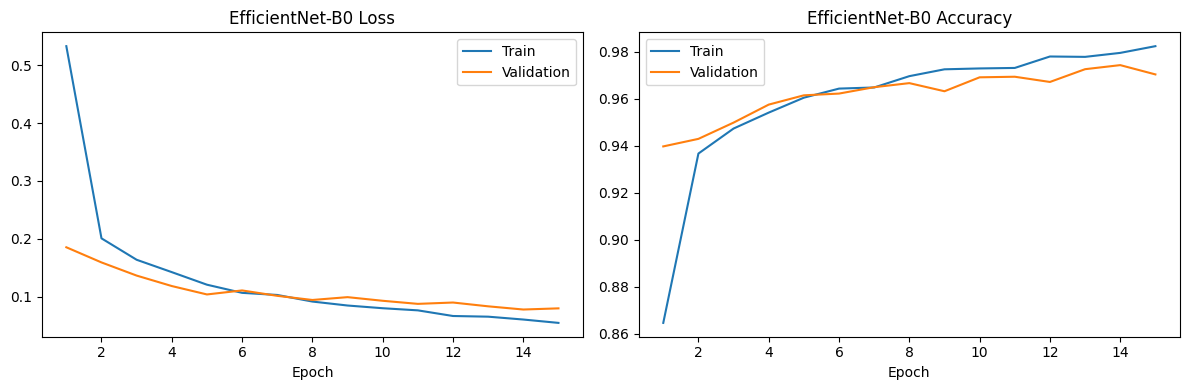

In [28]:
EFF_NUM_EPOCHS = 15
EFF_PATIENCE = 6
efficientnet_best_val_loss = float("inf")
efficientnet_best_epoch = 0
efficientnet_best_state = None
efficientnet_wait = 0
efficientnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

efficientnet_training_start = time.perf_counter()
for epoch in range(1, EFF_NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = run_model_epoch(
        efficientnet_model, train_loader, eff_criterion, eff_optimizer
    )
    val_loss, val_accuracy = run_model_epoch(
        efficientnet_model, val_loader, eff_criterion
    )

    efficientnet_history["train_loss"].append(train_loss)
    efficientnet_history["val_loss"].append(val_loss)
    efficientnet_history["train_accuracy"].append(train_accuracy)
    efficientnet_history["val_accuracy"].append(val_accuracy)

    if val_loss < efficientnet_best_val_loss:
        efficientnet_best_val_loss = val_loss
        efficientnet_best_epoch = epoch
        efficientnet_best_state = copy.deepcopy(efficientnet_model.state_dict())
        efficientnet_wait = 0
    else:
        efficientnet_wait += 1

    print(
        f"Epoch {epoch:02d}/{EFF_NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{time.perf_counter() - epoch_start:.1f}s"
    )
    if efficientnet_wait >= EFF_PATIENCE:
        print(f"Early stopping: validation loss did not improve for {EFF_PATIENCE} epochs.")
        break

efficientnet_training_seconds = time.perf_counter() - efficientnet_training_start
if efficientnet_best_state is None:
    raise RuntimeError("EfficientNet training did not produce a best validation checkpoint.")
efficientnet_model.load_state_dict(efficientnet_best_state)
print(
    f"Best epoch: {efficientnet_best_epoch} | "
    f"best validation loss: {efficientnet_best_val_loss:.4f} | "
    f"training time: {efficientnet_training_seconds:.1f}s"
)

eff_epochs = range(1, len(efficientnet_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eff_epochs, efficientnet_history["train_loss"], label="Train")
axes[0].plot(eff_epochs, efficientnet_history["val_loss"], label="Validation")
axes[0].set(title="EfficientNet-B0 Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(eff_epochs, efficientnet_history["train_accuracy"], label="Train")
axes[1].plot(eff_epochs, efficientnet_history["val_accuracy"], label="Validation")
axes[1].set(title="EfficientNet-B0 Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 28. Save the Best EfficientNet-B0 Checkpoint

Save the validation-selected weights and the preprocessing/class metadata. The checkpoint is written only after the training cell has completed.

In [29]:
if efficientnet_best_state is None:
    raise RuntimeError("Run EfficientNet training before saving the checkpoint.")
EFFICIENTNET_MODEL_PATH = LOCAL_CHECKPOINT_DIR / "best_efficientnet_b0_eurosat_two_blocks.pth"
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_checkpoint = {
    "format_version": 2,
    "architecture": "efficientnet_b0",
    "input_channels": 3,
    "model_state_dict": {
        key: value.detach().cpu().clone()
        for key, value in efficientnet_model.state_dict().items()
    },
    "class_names": list(class_names),
    "class_to_idx": {name: i for i, name in enumerate(class_names)},
    "image_size": int(IMAGE_SIZE),
    "imagenet_mean": list(IMAGENET_MEAN),
    "imagenet_std": list(IMAGENET_STD),
    "best_epoch": int(efficientnet_best_epoch),
    "best_validation_loss": float(efficientnet_best_val_loss),
    "training_seconds": float(efficientnet_training_seconds),
    "dataset": "EuroSAT RGB",
    "seed": int(SEED),
}
EFFICIENTNET_PERSISTENT_CHECKPOINT_PATH = save_verified_checkpoint(
    efficientnet_checkpoint, EFFICIENTNET_MODEL_PATH
)
print(f"Checkpoint size: {EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MiB")


SAVED & VERIFIED locally: /content/checkpoints/run_20261121_003103_UTC/best_efficientnet_b0_eurosat_two_blocks.pth
SAVED & VERIFIED persistently: /content/drive/MyDrive/Land_Type_Classification/checkpoints/run_20261121_003103_UTC/best_efficientnet_b0_eurosat_two_blocks.pth
Checkpoint size: 15.62 MiB


## 29. EfficientNet-B0 Final Test Evaluation

Evaluate the validation-selected EfficientNet model on the held-out test loader. This is the final test evaluation for EfficientNet; do not use these results to tune it.

In [30]:
if efficientnet_best_state is None:
    raise RuntimeError("Run EfficientNet training before test evaluation.")
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_model.eval()

efficientnet_test_labels = []
efficientnet_test_predictions = []
efficientnet_test_probabilities = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = efficientnet_model(images)
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
        efficientnet_test_probabilities.extend(probabilities)
        efficientnet_test_predictions.extend(probabilities.argmax(axis=1))
        efficientnet_test_labels.extend(labels.numpy())

efficientnet_test_probabilities = np.asarray(efficientnet_test_probabilities)
efficientnet_test_accuracy = accuracy_score(
    efficientnet_test_labels, efficientnet_test_predictions
)
print(f"EfficientNet-B0 test accuracy: {efficientnet_test_accuracy:.4f}")
print("Test images:", len(efficientnet_test_labels))

EfficientNet-B0 test accuracy: 0.9704
Test images: 4050


### Fine-tuning comparison — original vs revised EfficientNet-B0

The *previous saved notebook run* used `features[-1] + classifier`, `EFF_PATIENCE=4`, and obtained **96.05%** held-out test accuracy. The revised run uses `features[-2] + features[-1] + classifier`, `EFF_PATIENCE=6`, and writes to **`best_efficientnet_b0_eurosat_two_blocks.pth`** so the old checkpoint filename remains unchanged.

This is a useful architecture-sensitivity experiment, but trainable parameter fractions and computational budgets still differ from ResNet50; unfreezing more layers alone does not make the architectures perfectly comparable. Also, rerunning and tuning based on the same test set weakens its status as a strictly untouched final test set.

In [31]:
# Reports the new result only after the revised training/evaluation cells run.
# The historical accuracy is read from the previous notebook's saved output.
OLD_EFFICIENTNET_TEST_ACCURACY = 0.9605
assert "efficientnet_test_accuracy" in globals(), "Run the EfficientNet training and test-evaluation cells first."
eff_delta_pp = 100 * (efficientnet_test_accuracy - OLD_EFFICIENTNET_TEST_ACCURACY)
print(f"Previous EfficientNet-B0 test accuracy (1 feature stage): {OLD_EFFICIENTNET_TEST_ACCURACY:.2%}")
print(f"Revised EfficientNet-B0 test accuracy (2 stages):      {efficientnet_test_accuracy:.2%}")
print(f"Change from previous run: {eff_delta_pp:+.2f} percentage points")
print("Reminder: the test-set comparison is exploratory; do not optimize repeatedly against test accuracy.")


Previous EfficientNet-B0 test accuracy (1 feature stage): 96.05%
Revised EfficientNet-B0 test accuracy (2 stages):      97.04%
Change from previous run: +0.99 percentage points
Reminder: the test-set comparison is exploratory; do not optimize repeatedly against test accuracy.


## 30. EfficientNet Confusion Matrix and Classification Report

Inspect class-by-class test performance and the most frequent error patterns for EfficientNet-B0.

                      precision    recall  f1-score   support

          AnnualCrop     0.9725    0.9422    0.9571       450
              Forest     0.9803    0.9978    0.9890       450
HerbaceousVegetation     0.9513    0.9556    0.9534       450
             Highway     0.9654    0.9680    0.9667       375
          Industrial     0.9894    0.9920    0.9907       375
             Pasture     0.9353    0.9633    0.9491       300
       PermanentCrop     0.9412    0.9387    0.9399       375
         Residential     0.9911    0.9911    0.9911       450
               River     0.9653    0.9653    0.9653       375
             SeaLake     0.9977    0.9844    0.9911       450

            accuracy                         0.9704      4050
           macro avg     0.9690    0.9698    0.9693      4050
        weighted avg     0.9705    0.9704    0.9704      4050



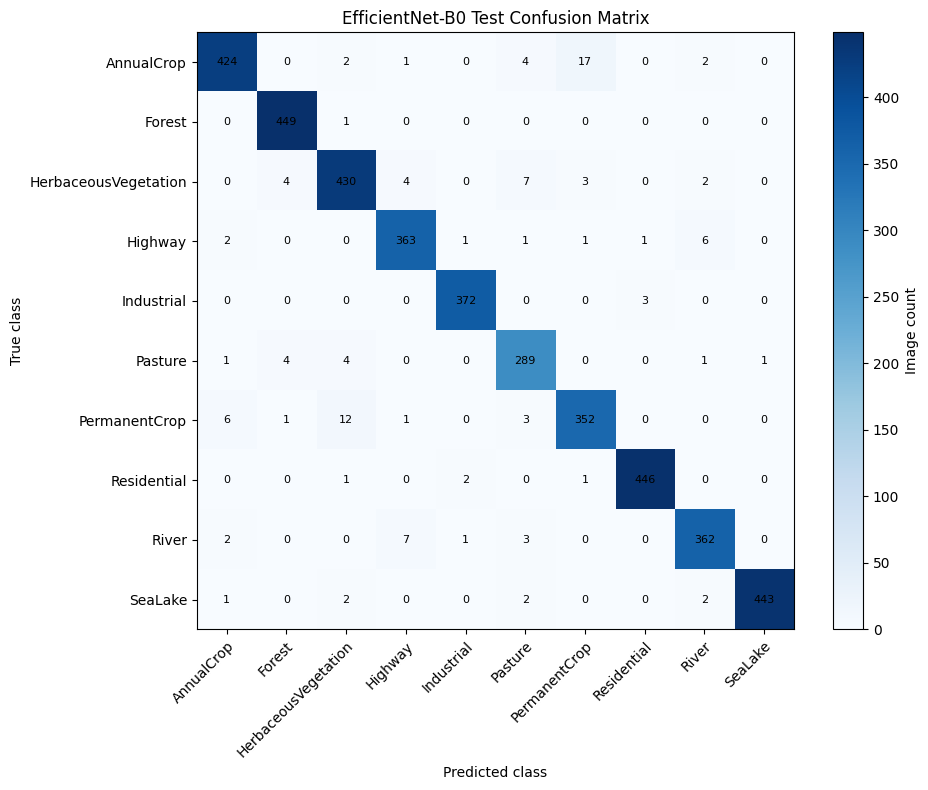

In [32]:
efficientnet_confusion = confusion_matrix(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
)
efficientnet_report_dict = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    digits=4,
    zero_division=0,
)
print(classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(efficientnet_confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EfficientNet-B0 Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(efficientnet_confusion[row, column]),
                ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 31. ResNet50 vs EfficientNet-B0 Comparison

Both models are evaluated on the same 4,050 held-out RGB patches. Training times are measured in the current run; no hardcoded timing from older experiments is used. This is descriptive reporting, not a reason to retune the test set.


,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB)
0,ResNet50,0.9790,0.9785,0.9789,0.9786,746.4859,90.0542
1,EfficientNet-B0,0.9704,0.9690,0.9698,0.9693,956.0042,15.6161


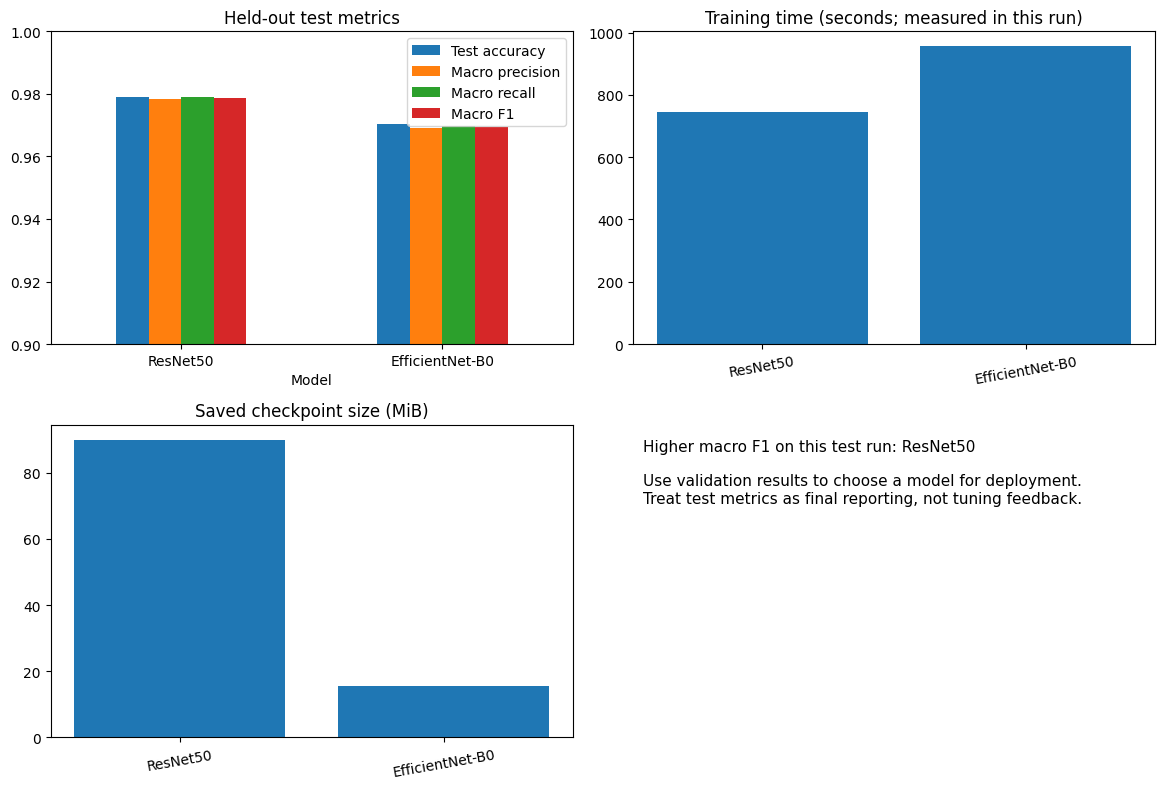

In [33]:
if not Path(MODEL_PATH).exists():
    raise FileNotFoundError("Run the ResNet50 model-saving cell before this comparison.")
if not Path(EFFICIENTNET_MODEL_PATH).exists():
    raise FileNotFoundError("Run the EfficientNet training and checkpoint cells first.")

efficientnet_report_for_comparison = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
model_comparison = pd.DataFrame([
    {
        "Model": "ResNet50",
        "Test accuracy": accuracy_score(all_labels, all_predictions),
        "Macro precision": baseline_report_dict["macro avg"]["precision"],
        "Macro recall": baseline_report_dict["macro avg"]["recall"],
        "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
        "Training time (s)": baseline_training_seconds,
        "Checkpoint size (MiB)": Path(MODEL_PATH).stat().st_size / (1024 ** 2),
    },
    {
        "Model": "EfficientNet-B0",
        "Test accuracy": efficientnet_test_accuracy,
        "Macro precision": efficientnet_report_for_comparison["macro avg"]["precision"],
        "Macro recall": efficientnet_report_for_comparison["macro avg"]["recall"],
        "Macro F1": efficientnet_report_for_comparison["macro avg"]["f1-score"],
        "Training time (s)": efficientnet_training_seconds,
        "Checkpoint size (MiB)": EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2),
    },
])
display(model_comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metric_columns = ["Test accuracy", "Macro precision", "Macro recall", "Macro F1"]
model_comparison.set_index("Model")[metric_columns].plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Held-out test metrics")
axes[0, 0].set_ylim(0.90, 1.0)
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 1].bar(model_comparison["Model"], model_comparison["Training time (s)"])
axes[0, 1].set_title("Training time (seconds; measured in this run)")
axes[0, 1].tick_params(axis="x", rotation=10)
axes[1, 0].bar(model_comparison["Model"], model_comparison["Checkpoint size (MiB)"])
axes[1, 0].set_title("Saved checkpoint size (MiB)")
axes[1, 0].tick_params(axis="x", rotation=10)
axes[1, 1].axis("off")
f1_winner = model_comparison.loc[model_comparison["Macro F1"].idxmax(), "Model"]
axes[1, 1].text(
    0.02, 0.75,
    f"Higher macro F1 on this test run: {f1_winner}\n\n"
    "Use validation results to choose a model for deployment.\n"
    "Treat test metrics as final reporting, not tuning feedback.",
    fontsize=11,
)
plt.tight_layout()
plt.show()

## 32. Per-Class Performance and Most Confused Classes

Compare per-class precision, recall, and F1, then list the largest off-diagonal errors. These tables explain which land-cover classes are hardest for each model.

In [34]:
baseline_confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
baseline_report_for_comparison = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

per_class_comparison = pd.DataFrame({
    "Class": class_names,
    "ResNet50 precision": [baseline_report_for_comparison[name]["precision"] for name in class_names],
    "ResNet50 recall": [baseline_report_for_comparison[name]["recall"] for name in class_names],
    "ResNet50 F1": [baseline_report_for_comparison[name]["f1-score"] for name in class_names],
    "EfficientNet precision": [efficientnet_report_for_comparison[name]["precision"] for name in class_names],
    "EfficientNet recall": [efficientnet_report_for_comparison[name]["recall"] for name in class_names],
    "EfficientNet F1": [efficientnet_report_for_comparison[name]["f1-score"] for name in class_names],
})
display(per_class_comparison.round(4))

def top_confusion_pairs(matrix, labels, top_n=5):
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pairs = []
    for true_index, predicted_index in zip(*np.where(off_diagonal > 0)):
        pairs.append({
            "True class": labels[true_index],
            "Predicted as": labels[predicted_index],
            "Count": int(off_diagonal[true_index, predicted_index]),
        })
    if not pairs:
        return pd.DataFrame(columns=["True class", "Predicted as", "Count"])
    return pd.DataFrame(pairs).sort_values("Count", ascending=False).head(top_n)

print("ResNet50: most frequent confusion pairs")
display(top_confusion_pairs(baseline_confusion, class_names))
print("EfficientNet-B0: most frequent confusion pairs")
display(top_confusion_pairs(efficientnet_confusion, class_names))

,Class,ResNet50 precision,ResNet50 recall,ResNet50 F1,EfficientNet precision,EfficientNet recall,EfficientNet F1
0,AnnualCrop,0.9796,0.9600,0.9697,0.9725,0.9422,0.9571
1,Forest,0.9889,0.9933,0.9911,0.9803,0.9978,0.9890
2,HerbaceousVegetation,0.9667,0.9667,0.9667,0.9513,0.9556,0.9534
3,Highway,0.9587,0.9893,0.9738,0.9654,0.9680,0.9667
4,Industrial,0.9919,0.9840,0.9880,0.9894,0.9920,0.9907
5,Pasture,0.9767,0.9767,0.9767,0.9353,0.9633,0.9491
6,PermanentCrop,0.9449,0.9600,0.9524,0.9412,0.9387,0.9399
7,Residential,0.9912,0.9956,0.9933,0.9911,0.9911,0.9911
8,River,0.9866,0.9787,0.9826,0.9653,0.9653,0.9653
9,SeaLake,1.0000,0.9844,0.9922,0.9977,0.9844,0.9911


ResNet50: most frequent confusion pairs


,True class,Predicted as,Count
3,AnnualCrop,PermanentCrop,12
9,HerbaceousVegetation,PermanentCrop,9
25,River,Highway,8
15,Pasture,HerbaceousVegetation,5
18,PermanentCrop,HerbaceousVegetation,5


EfficientNet-B0: most frequent confusion pairs


,True class,Predicted as,Count
3,AnnualCrop,PermanentCrop,17
25,PermanentCrop,HerbaceousVegetation,12
8,HerbaceousVegetation,Pasture,7
32,River,Highway,7
16,Highway,River,6


## 33. Correct and Incorrect Prediction Examples with Confidence

Visualize representative ResNet50 predictions from the held-out test set. Confidence is the model's softmax score for its predicted class; it is not a guarantee that the prediction is correct.

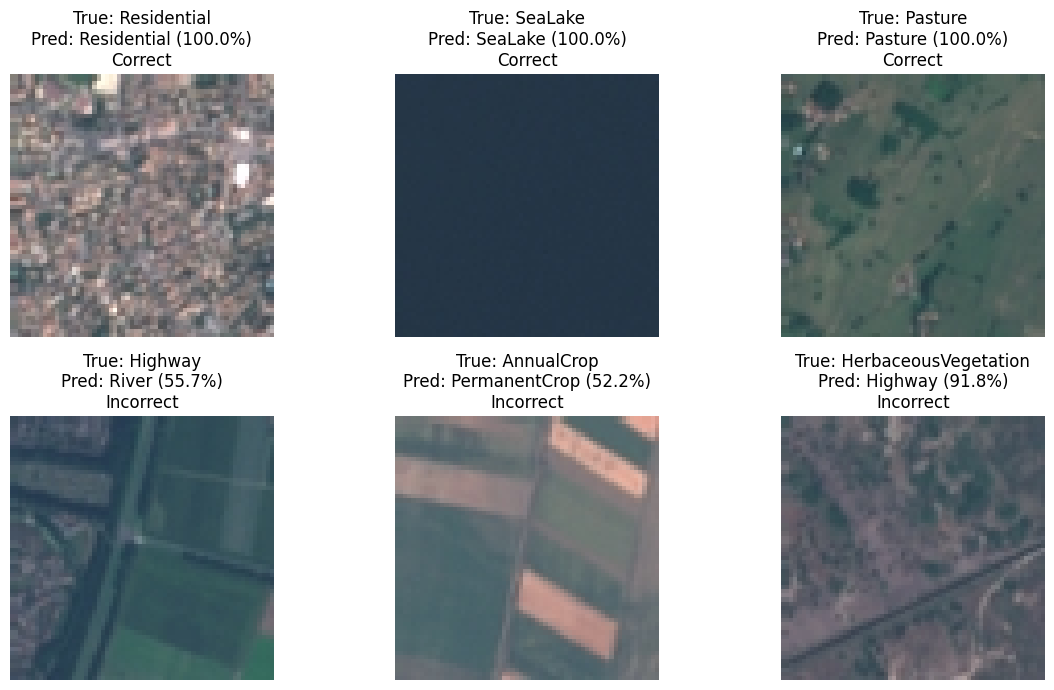

In [35]:
baseline_true_array = np.asarray(all_labels)
baseline_pred_array = np.asarray(all_predictions)
correct_positions = np.flatnonzero(baseline_true_array == baseline_pred_array)[:3]
incorrect_positions = np.flatnonzero(baseline_true_array != baseline_pred_array)[:3]
example_positions = list(correct_positions) + list(incorrect_positions)
if len(incorrect_positions) == 0:
    print("No incorrect test predictions are available to display.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    axes = axes.ravel()
    for axis, test_position in zip(axes, example_positions):
        normalized_tensor, true_label = test_set[int(test_position)]
        original_dataset_index = test_set.indices[int(test_position)]
        original_image, _ = dataset[original_dataset_index]
        input_tensor = normalized_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            probabilities = torch.softmax(loaded_model(input_tensor), dim=1)[0]
        predicted_index = int(probabilities.argmax().item())
        confidence = float(probabilities[predicted_index].item())
        is_correct = predicted_index == int(true_label)
        axis.imshow(original_image)
        axis.set_title(
            f"True: {class_names[int(true_label)]}\n"
            f"Pred: {class_names[predicted_index]} ({confidence:.1%})\n"
            f"{'Correct' if is_correct else 'Incorrect'}"
        )
        axis.axis("off")
    for axis in axes[len(example_positions):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 34. Explainability with Grad-CAM

Grad-CAM uses gradients flowing into a final convolutional layer to create a coarse heatmap of image regions that support a chosen class score. The implementation below explains ResNet50 predictions, including one correct and one incorrect test example. Heatmaps are diagnostic visualizations, not proof of causal reasoning. [Original Grad-CAM paper](https://arxiv.org/abs/1610.02391).

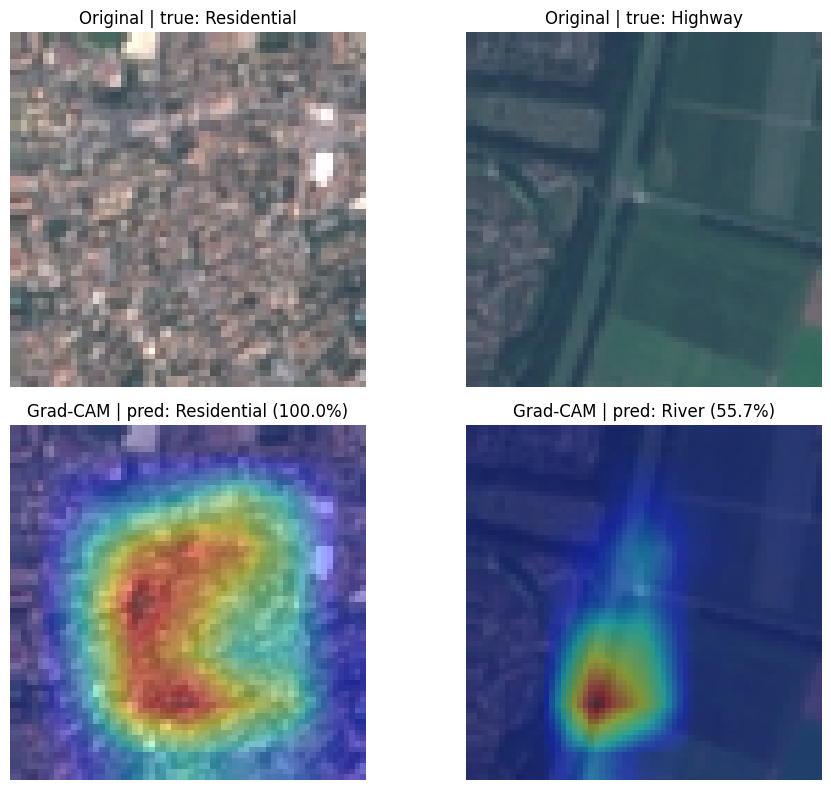

In [36]:
import torch.nn.functional as F

def generate_gradcam(model_to_explain, target_layer, image_tensor, output_size):
    activations = {}
    gradients = {}

    def capture_activation(module, inputs, output):
        activations["feature"] = output
        output.register_hook(lambda gradient: gradients.__setitem__("feature", gradient.detach()))

    hook_handle = target_layer.register_forward_hook(capture_activation)
    model_to_explain.eval()
    model_to_explain.zero_grad(set_to_none=True)
    input_batch = image_tensor.unsqueeze(0).to(device)
    logits = model_to_explain(input_batch)
    predicted_index = int(logits.argmax(dim=1).item())
    score = logits[:, predicted_index].sum()
    score.backward()
    hook_handle.remove()

    feature_maps = activations["feature"].detach()
    feature_gradients = gradients["feature"]
    channel_weights = feature_gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((channel_weights * feature_maps).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=output_size, mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / cam.max().clamp_min(1e-8)
    confidence = torch.softmax(logits.detach(), dim=1)[0, predicted_index].item()
    return predicted_index, confidence, cam.cpu().numpy()

if len(correct_positions) == 0 or len(incorrect_positions) == 0:
    raise RuntimeError("Grad-CAM examples require at least one correct and one incorrect test prediction.")

gradcam_positions = [int(correct_positions[0]), int(incorrect_positions[0])]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for column, test_position in enumerate(gradcam_positions):
    normalized_tensor, true_label = test_set[test_position]
    original_dataset_index = test_set.indices[test_position]
    original_image, _ = dataset[original_dataset_index]
    heatmap_size = (original_image.height, original_image.width)
    predicted_index, confidence, heatmap = generate_gradcam(
        loaded_model, loaded_model.layer4, normalized_tensor, heatmap_size
    )
    axes[0, column].imshow(original_image)
    axes[0, column].set_title(f"Original | true: {class_names[int(true_label)]}")
    axes[1, column].imshow(original_image)
    axes[1, column].imshow(heatmap, cmap="jet", alpha=0.40)
    axes[1, column].set_title(
        f"Grad-CAM | pred: {class_names[predicted_index]} ({confidence:.1%})"
    )
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()

## 35. Multispectral EuroSAT: Separate Extension Plan

The current model uses three RGB channels. The original EuroSAT release also provides EuroSAT_MS.zip with all 13 Sentinel-2 bands in their original value range; these must be treated as a separate dataset and preprocessing pipeline. Sentinel-2 bands have native 10 m, 20 m, or 60 m resolutions, so alignment and per-band scaling must be checked before training. Sources: [EuroSAT paper](https://arxiv.org/abs/1709.00029), [EuroSAT Zenodo record](https://zenodo.org/records/7711097), and [Sentinel-2 product specification](https://sentinels.copernicus.eu/documents/d/sentinel/sentinel-2-products-specification-document-15_1).

In [37]:
multispectral_comparison = pd.DataFrame([
    {"Input": "RGB EuroSAT", "Channels": 3, "Typical tensor": "[B, 3, 64, 64] before resize", "Preprocessing": "RGB conversion, ImageNet normalization"},
    {"Input": "EuroSAT multispectral", "Channels": 13, "Typical tensor": "[B, 13, 64, 64]", "Preprocessing": "Align bands; inspect original range; normalize each band using training data only"},
])
display(multispectral_comparison)

sentinel_band_groups = pd.DataFrame([
    {"Native resolution": "10 m", "Sentinel-2 bands": "B2, B3, B4, B8"},
    {"Native resolution": "20 m", "Sentinel-2 bands": "B5, B6, B7, B8A, B11, B12"},
    {"Native resolution": "60 m", "Sentinel-2 bands": "B1, B9, B10"},
])
display(sentinel_band_groups)

def adapt_resnet50_first_layer_to_13_bands(num_classes=NUM_CLASSES, num_bands=13):
    """Create a separate 13-channel ResNet50; this does not modify either RGB model."""
    multispectral_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    old_conv = multispectral_model.conv1
    new_conv = nn.Conv2d(
        in_channels=num_bands,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    with torch.no_grad():
        mean_rgb_kernel = old_conv.weight.mean(dim=1, keepdim=True)
        new_conv.weight.copy_(mean_rgb_kernel.repeat(1, num_bands, 1, 1) * (3 / num_bands))
    multispectral_model.conv1 = new_conv
    multispectral_model.fc = nn.Linear(multispectral_model.fc.in_features, num_classes)
    return multispectral_model

print("The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.")

,Input,Channels,Typical tensor,Preprocessing
0,RGB EuroSAT,3,"[B, 3, 64, 64] before resize","RGB conversion, ImageNet normalization"
1,EuroSAT multispectral,13,"[B, 13, 64, 64]",Align bands; inspect original range; normalize...


,Native resolution,Sentinel-2 bands
0,10 m,"B2, B3, B4, B8"
1,20 m,"B5, B6, B7, B8A, B11, B12"
2,60 m,"B1, B9, B10"


The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.


## 36. Practical Optimization Options

The existing pipelines already use transfer learning, early stopping, and best-checkpoint selection. For a new controlled experiment, reduce the learning rate when validation loss plateaus; apply the same policy to both architectures if comparing them. Tune only on the validation set, never on test results.

In [38]:
def make_validation_lr_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    )

# Optional for a future training run:
# scheduler = make_validation_lr_scheduler(optimizer)
# After each validation epoch, call: scheduler.step(val_loss)
# Keep this experiment separate from the already-reported baseline results.

optimization_experiments = pd.DataFrame([
    {"Experiment": "Learning-rate schedule", "Selection data": "Validation", "Purpose": "Reduce learning rate after a validation-loss plateau"},
    {"Experiment": "Unfreeze more/less layers", "Selection data": "Validation", "Purpose": "Trade adaptation capacity against compute and overfitting"},
    {"Experiment": "Batch size / learning rate", "Selection data": "Validation", "Purpose": "Measure stability and GPU memory use"},
])
display(optimization_experiments)

,Experiment,Selection data,Purpose
0,Learning-rate schedule,Validation,Reduce learning rate after a validation-loss p...
1,Unfreeze more/less layers,Validation,Trade adaptation capacity against compute and ...
2,Batch size / learning rate,Validation,Measure stability and GPU memory use


## 37. Inference Speed Measurement

Measure single-image inference after warm-up for both trained models on the same device. This is a runtime benchmark, not a change to model weights or test-set metrics.

In [39]:
def benchmark_single_image(model_to_benchmark, image_tensor, warmup=10, iterations=50):
    model_to_benchmark.eval()
    input_batch = image_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_time = time.perf_counter()
        for _ in range(iterations):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
    average_ms = (time.perf_counter() - start_time) * 1000 / iterations
    return average_ms

benchmark_image, _ = test_set[0]
speed_results = pd.DataFrame([
    {"Model": "ResNet50", "Average single-image latency (ms)": benchmark_single_image(loaded_model, benchmark_image)},
    {"Model": "EfficientNet-B0", "Average single-image latency (ms)": benchmark_single_image(efficientnet_model, benchmark_image)},
])
speed_results["Images per second (approx.)"] = 1000 / speed_results["Average single-image latency (ms)"]
display(speed_results.round(2))

,Model,Average single-image latency (ms),Images per second (approx.)
0,ResNet50,6.30,158.83
1,EfficientNet-B0,8.06,124.00


# Phase 3 — EuroSAT Multispectral Classification

The 13-band Sentinel-2 GeoTIFF data come from the [official EuroSAT Zenodo record](https://zenodo.org/records/7711810), file `EuroSAT_MS.zip`. This differs from the RGB JPEG archive. For a valid paired comparison, the **same class/filename keys and RGB split** are required; a missing or mismatched file must fail explicitly instead of silently creating a different test split.

**Run All performs the full ~2.1 GB download, checks its MD5, scans training-only band statistics, and trains a 13-channel ResNet50.** Use Colab with a GPU and enough free disk space. The checkpoint retains the original 13-band ordering and the normalization statistics needed by the future website.


## 41. Baseline and Class Mapping

The original cells and results remain intact. This section reuses their 10-class order and, when TIFF and RGB filenames correspond exactly, the same train/validation/test sample split. Otherwise the multispectral pipeline creates a fixed-seed stratified 70/15/15 split.

Expected output: the existing class names and the 18,900 / 4,050 / 4,050 RGB split sizes.


In [40]:
# Use the class mapping and split already established by the RGB notebook.
if "class_names" not in globals() or "targets" not in globals():
    raise RuntimeError("Run the original RGB data-loading and split cells before this multispectral phase.")
if "dataset" not in globals() or not hasattr(dataset, "samples"):
    raise RuntimeError("The original EuroSAT RGB ImageFolder dataset is required for class/split matching.")

MS_CLASS_NAMES = list(class_names)
MS_CLASS_TO_IDX = {name: index for index, name in enumerate(MS_CLASS_NAMES)}
MS_NUM_CLASSES = len(MS_CLASS_NAMES)
EUROSAT_MS_BAND_ORDER = [
    "B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08",
    "B09", "B10", "B11", "B12", "B8A",
]
assert MS_NUM_CLASSES == 10, f"Expected 10 classes, found {MS_NUM_CLASSES}."
assert len(EUROSAT_MS_BAND_ORDER) == 13

if hasattr(dataset, "class_to_idx"):
    assert dataset.class_to_idx == MS_CLASS_TO_IDX, (
        "The RGB class order differs from the existing class_names mapping."
    )

print("RGB class mapping reused:")
for class_name, class_index in MS_CLASS_TO_IDX.items():
    print(f"  {class_index}: {class_name}")
print("RGB split sizes:", len(train_indices), len(val_indices), len(test_indices))
print("EuroSAT MS band order:", ", ".join(EUROSAT_MS_BAND_ORDER))


RGB class mapping reused:
  0: AnnualCrop
  1: Forest
  2: HerbaceousVegetation
  3: Highway
  4: Industrial
  5: Pasture
  6: PermanentCrop
  7: Residential
  8: River
  9: SeaLake
RGB split sizes: 18900 4050 4050
EuroSAT MS band order: B01, B02, B03, B04, B05, B06, B07, B08, B09, B10, B11, B12, B8A


## 42. Rasterio Setup

Rasterio opens GeoTIFFs as band-first arrays with shape (bands, rows, columns). The code below checks band count and metadata directly from each TIFF rather than treating the multispectral archive as RGB.

Expected output: Rasterio version and the canonical 13-channel band order.


In [41]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

import rasterio
print("Rasterio version:", rasterio.__version__)
print("A Rasterio read is organized as (bands, rows, columns).")


Rasterio version: 1.5.2
A Rasterio read is organized as (bands, rows, columns).


## 43. Download the Official Multispectral Archive

The correct Zenodo asset is EuroSAT_MS.zip (MD5: 091174add3c8e680a49244acf185b9f0). The download cell verifies that checksum before extraction and rejects unsafe archive paths.

Expected output: a verified archive and the discovered folder containing the 10 class subfolders.


In [42]:
import hashlib
import os
import zipfile
from pathlib import Path

import requests

MS_DOWNLOAD_URL = "https://zenodo.org/records/7711810/files/EuroSAT_MS.zip?download=1"
MS_EXPECTED_MD5 = "091174add3c8e680a49244acf185b9f0"
MS_WORK_DIR = Path("/content/eurosat_multispectral")
MS_WORK_DIR.mkdir(parents=True, exist_ok=True)
MS_ZIP_PATH = MS_WORK_DIR / "EuroSAT_MS.zip"
MS_EXTRACT_DIR = MS_WORK_DIR / "extracted"

if not MS_ZIP_PATH.exists():
    partial_path = MS_ZIP_PATH.with_suffix(".zip.part")
    print("Downloading EuroSAT_MS.zip from Zenodo (approximately 2.1 GB)...")
    with requests.get(MS_DOWNLOAD_URL, stream=True, timeout=(60, 300)) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("content-length", 0))
        downloaded_bytes = 0
        last_reported_mb = -1
        with partial_path.open("wb") as output_file:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if not chunk:
                    continue
                output_file.write(chunk)
                downloaded_bytes += len(chunk)
                downloaded_mb = downloaded_bytes // (1024 * 1024)
                if downloaded_mb // 100 != last_reported_mb // 100:
                    total_text = f" / {total_bytes // (1024 * 1024):,} MiB" if total_bytes else ""
                    print(f"Downloaded {downloaded_mb:,} MiB{total_text}")
                    last_reported_mb = downloaded_mb
    os.replace(partial_path, MS_ZIP_PATH)

md5 = hashlib.md5()
with MS_ZIP_PATH.open("rb") as archive_file:
    for chunk in iter(lambda: archive_file.read(8 * 1024 * 1024), b""):
        md5.update(chunk)
actual_md5 = md5.hexdigest()
if actual_md5.lower() != MS_EXPECTED_MD5:
    raise ValueError(
        f"EuroSAT MS checksum mismatch: expected {MS_EXPECTED_MD5}, got {actual_md5}"
    )
print(f"Verified archive checksum: {actual_md5}")

archive_has_tiffs = (
    any(path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
        for path in MS_EXTRACT_DIR.rglob("*"))
    if MS_EXTRACT_DIR.exists() else False
)
if not archive_has_tiffs:
    MS_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(MS_ZIP_PATH) as archive:
        unsafe_members = [
            member.filename for member in archive.infolist()
            if Path(member.filename).is_absolute() or ".." in Path(member.filename).parts
        ]
        if unsafe_members:
            raise ValueError(f"Unsafe path found in archive: {unsafe_members[:3]}")
        archive.extractall(MS_EXTRACT_DIR)

candidate_class_dirs = [
    path for path in MS_EXTRACT_DIR.rglob(MS_CLASS_NAMES[0])
    if path.is_dir()
    and all((path.parent / class_name).is_dir() for class_name in MS_CLASS_NAMES)
]
if not candidate_class_dirs:
    raise FileNotFoundError(
        "Could not find a directory containing all expected EuroSAT class folders."
    )
MS_CLASS_ROOT = sorted(candidate_class_dirs, key=lambda path: len(path.parts))[0].parent
print("Multispectral class root:", MS_CLASS_ROOT)


Downloaded 8 MiB / 1,969 MiB
Downloaded 104 MiB / 1,969 MiB
Downloaded 200 MiB / 1,969 MiB
Downloaded 304 MiB / 1,969 MiB
Downloaded 400 MiB / 1,969 MiB
Downloaded 504 MiB / 1,969 MiB
Downloaded 600 MiB / 1,969 MiB
Downloaded 704 MiB / 1,969 MiB
Downloaded 800 MiB / 1,969 MiB
Downloaded 904 MiB / 1,969 MiB
Downloaded 1,000 MiB / 1,969 MiB
Downloaded 1,104 MiB / 1,969 MiB
Downloaded 1,200 MiB / 1,969 MiB
Downloaded 1,304 MiB / 1,969 MiB
Downloaded 1,400 MiB / 1,969 MiB
Downloaded 1,504 MiB / 1,969 MiB
Downloaded 1,600 MiB / 1,969 MiB
Downloaded 1,704 MiB / 1,969 MiB
Downloaded 1,800 MiB / 1,969 MiB
Downloaded 1,904 MiB / 1,969 MiB
Verified archive checksum: 091174add3c8e680a49244acf185b9f0
Multispectral class root: /content/eurosat_multispectral/extracted/EuroSAT_MS


## 44. Inspect TIFF Structure, Labels, and Values

The notebook inventories every TIFF's class, dimensions, number of bands, and dtype. It reads a small reproducible class-balanced sample to report pixel ranges; the sample range is explicitly labeled as a sample, while class counts and structural checks cover the full archive.

Expected output: 27,000 TIFFs, 13 bands per image, dimension/dtype counts, class distribution, and sampled per-band ranges.


In [43]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

import rasterio
from collections import Counter
import numpy as np
import pandas as pd

MS_RECORDS = []

for class_name in MS_CLASS_NAMES:
    class_dir = MS_CLASS_ROOT / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(f"Missing class directory: {class_dir}")

    class_paths = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
    )

    for path in class_paths:
        MS_RECORDS.append({
            "path": path,
            "class_name": class_name,
            "label": MS_CLASS_TO_IDX[class_name],
        })

if not MS_RECORDS:
    raise RuntimeError("No TIFF images found in the EuroSAT MS class folders.")

metadata_rows = []
invalid_band_files = []

for record in MS_RECORDS:
    with rasterio.open(record["path"]) as src:
        row = {
            "class": record["class_name"],
            "path": str(record["path"]),
            "width": src.width,
            "height": src.height,
            "band_count": src.count,
            "dtypes": ",".join(src.dtypes),
            "nodata": str(src.nodatavals),
            "descriptions": str(src.descriptions),
        }
        metadata_rows.append(row)

        if src.count != 13:
            invalid_band_files.append((str(record["path"]), src.count))

if invalid_band_files:
    raise ValueError(
        f"Found TIFFs without exactly 13 bands; examples: {invalid_band_files[:5]}"
    )

MS_METADATA = pd.DataFrame(metadata_rows)

MS_CLASS_COUNTS = Counter(record["class_name"] for record in MS_RECORDS)
MS_CLASS_DISTRIBUTION = pd.DataFrame({
    "Class": MS_CLASS_NAMES,
    "Images": [MS_CLASS_COUNTS[name] for name in MS_CLASS_NAMES],
})

print(f"Total multispectral TIFFs: {len(MS_RECORDS):,}")
print(
    "Unique dimensions:",
    sorted(set(zip(MS_METADATA["width"], MS_METADATA["height"])))
)
print("Band counts:", MS_METADATA["band_count"].value_counts().to_dict())

print("Dtype profiles:")
display(
    MS_METADATA.groupby(["dtypes", "band_count"])
    .size()
    .rename("files")
    .to_frame()
)

print("Class distribution:")
display(MS_CLASS_DISTRIBUTION)

rng = np.random.default_rng(int(globals().get("SEED", 42)))
sample_indices = []

for class_name in MS_CLASS_NAMES:
    indices = [
        i for i, record in enumerate(MS_RECORDS)
        if record["class_name"] == class_name
    ]

    sample_indices.extend(
        rng.choice(
            indices,
            size=min(3, len(indices)),
            replace=False
        ).tolist()
    )

sample_min = np.full(13, np.inf, dtype=np.float64)
sample_max = np.full(13, -np.inf, dtype=np.float64)

sample_descriptions = None
sample_dtypes = None
sample_nodata = None

for index in sample_indices:
    with rasterio.open(MS_RECORDS[index]["path"]) as src:
        data = src.read(out_dtype="float32")
        sample_descriptions = src.descriptions
        sample_dtypes = src.dtypes
        sample_nodata = src.nodatavals

        valid = np.isfinite(data) & (src.read_masks() > 0)

        for band_index, nodata_value in enumerate(src.nodatavals):
            if nodata_value is not None and np.isfinite(nodata_value):
                valid[band_index] &= data[band_index] != nodata_value

        # Treat a pixel as invalid only when all 13 band values are zero.
        valid &= ~np.all(data == 0, axis=0)[None, :, :]

        for band_index in range(13):
            values = data[band_index][valid[band_index]]

            if values.size:
                sample_min[band_index] = min(
                    sample_min[band_index],
                    float(values.min())
                )
                sample_max[band_index] = max(
                    sample_max[band_index],
                    float(values.max())
                )

MS_RANGE_SAMPLE = pd.DataFrame({
    "Band (official TIFF order)": EUROSAT_MS_BAND_ORDER,
    "Sample minimum": sample_min,
    "Sample maximum": sample_max,
})

print(
    f"Value ranges below come from "
    f"{len(sample_indices)} class-balanced TIFF samples:"
)
display(MS_RANGE_SAMPLE)

print("Example TIFF dtype:", sample_dtypes)
print("Example TIFF descriptions:", sample_descriptions)
print("Example TIFF nodata values:", sample_nodata)

Total multispectral TIFFs: 27,000
Unique dimensions: [(64, 64)]
Band counts: {13: 27000}
Dtype profiles:


,,files
dtypes,band_count,
"uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16",13,27000


Class distribution:


,Class,Images
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


Value ranges below come from 30 class-balanced TIFF samples:


,Band (official TIFF order),Sample minimum,Sample maximum
0,B01,1035.0,2734.0
1,B02,686.0,6605.0
2,B03,441.0,7175.0
3,B04,233.0,9926.0
4,B05,238.0,5826.0
5,B06,217.0,6424.0
6,B07,205.0,7149.0
7,B08,157.0,9606.0
8,B09,51.0,2099.0
9,B10,4.0,41.0


Example TIFF dtype: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
Example TIFF descriptions: (None, None, None, None, None, None, None, None, None, None, None, None, None)
Example TIFF nodata values: (None, None, None, None, None, None, None, None, None, None, None, None, None)


## 45. Reuse the Exact RGB Train / Validation / Test Split

For a valid RGB-vs-multispectral comparison the 27,000 RGB and MS samples are matched by **(class, filename stem)**, labels are checked, and identical sample membership across all three splits is mandatory. Fail rather than silently evaluate on different held-out samples.


In [44]:
from sklearn.model_selection import train_test_split

MS_LABELS = np.asarray([record["label"] for record in MS_RECORDS], dtype=np.int64)
MS_KEYS = [
    (record["class_name"], record["path"].stem)
    for record in MS_RECORDS
]
if len(set(MS_KEYS)) != len(MS_KEYS):
    raise ValueError("Duplicate (class, filename stem) keys found in the MS archive.")

rgb_samples = list(dataset.samples)
rgb_key_to_index = {}
for rgb_index, (rgb_path, rgb_label) in enumerate(rgb_samples):
    rgb_class = MS_CLASS_NAMES[int(rgb_label)]
    key = (rgb_class, Path(rgb_path).stem)
    if key in rgb_key_to_index:
        raise ValueError(f"Duplicate RGB sample key: {key}")
    rgb_key_to_index[key] = rgb_index

ms_key_to_index = {key: index for index, key in enumerate(MS_KEYS)}
same_samples = set(rgb_key_to_index) == set(ms_key_to_index)
same_labels = same_samples and all(
    int(MS_LABELS[ms_key_to_index[key]]) == int(dataset.samples[rgb_key_to_index[key]][1])
    for key in rgb_key_to_index
)

if not (same_samples and same_labels):
    raise ValueError(
        "RGB and multispectral samples/labels do not match. "
        "Do not compare models on different test images."
    )

if same_samples and same_labels and all(
    name in globals() for name in ("train_indices", "val_indices", "test_indices")
):
    rgb_split_by_index = {}
    for split_name, indices in (
        ("train", train_indices),
        ("validation", val_indices),
        ("test", test_indices),
    ):
        for rgb_index in np.asarray(indices, dtype=np.int64):
            rgb_split_by_index[int(rgb_index)] = split_name
    MS_TRAIN_INDICES, MS_VAL_INDICES, MS_TEST_INDICES = [], [], []
    for ms_index, key in enumerate(MS_KEYS):
        rgb_index = rgb_key_to_index[key]
        split_name = rgb_split_by_index[rgb_index]
        if split_name == "train":
            MS_TRAIN_INDICES.append(ms_index)
        elif split_name == "validation":
            MS_VAL_INDICES.append(ms_index)
        else:
            MS_TEST_INDICES.append(ms_index)
    MS_SPLIT_MODE = "same RGB samples and same RGB split (filename/class keys matched)"
else:
    ms_all_indices = np.arange(len(MS_RECORDS))
    test_count = int(round(0.15 * len(ms_all_indices)))
    val_count = int(round(0.15 * len(ms_all_indices)))
    seed = int(globals().get("SEED", 42))
    ms_train_val, MS_TEST_INDICES = train_test_split(
        ms_all_indices,
        test_size=test_count,
        random_state=seed,
        stratify=MS_LABELS,
    )
    MS_TRAIN_INDICES, MS_VAL_INDICES = train_test_split(
        ms_train_val,
        test_size=val_count,
        random_state=seed,
        stratify=MS_LABELS[ms_train_val],
    )
    raise AssertionError("RGB split mapping missing; paired MS split is required")

MS_TRAIN_INDICES = np.asarray(MS_TRAIN_INDICES, dtype=np.int64)
MS_VAL_INDICES = np.asarray(MS_VAL_INDICES, dtype=np.int64)
MS_TEST_INDICES = np.asarray(MS_TEST_INDICES, dtype=np.int64)
assert not (set(MS_TRAIN_INDICES) & set(MS_VAL_INDICES))
assert not (set(MS_TRAIN_INDICES) & set(MS_TEST_INDICES))
assert not (set(MS_VAL_INDICES) & set(MS_TEST_INDICES))
assert len(MS_TRAIN_INDICES) + len(MS_VAL_INDICES) + len(MS_TEST_INDICES) == len(MS_RECORDS)
assert (len(MS_TRAIN_INDICES), len(MS_VAL_INDICES), len(MS_TEST_INDICES)) == (18_900, 4_050, 4_050)

MS_SPLIT_SUMMARY = pd.DataFrame({
    "Class": MS_CLASS_NAMES,
    "Train": np.bincount(MS_LABELS[MS_TRAIN_INDICES], minlength=MS_NUM_CLASSES),
    "Validation": np.bincount(MS_LABELS[MS_VAL_INDICES], minlength=MS_NUM_CLASSES),
    "Test": np.bincount(MS_LABELS[MS_TEST_INDICES], minlength=MS_NUM_CLASSES),
})
print("Multispectral split:", MS_SPLIT_MODE)
print(
    f"Train: {len(MS_TRAIN_INDICES):,} | "
    f"Validation: {len(MS_VAL_INDICES):,} | Test: {len(MS_TEST_INDICES):,}"
)
display(MS_SPLIT_SUMMARY)


Multispectral split: same RGB samples and same RGB split (filename/class keys matched)
Train: 18,900 | Validation: 4,050 | Test: 4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 46. TIFF Loader and Training-Only Band Statistics

Invalid pixels are identified from non-finite values, Rasterio masks, explicit per-band nodata values, and pixels that are zero in every band. Individual zero values are kept when the pixel has other valid measurements. Per-band mean and standard deviation are accumulated from training TIFFs only; validation and test data do not contribute.

Expected output: the 13 training-only means and standard deviations. These are recomputed from the current training split, not copied from a published dataset statistic.


In [45]:
import re

def _band_name_from_description(description):
    if not description:
        return None
    match = re.search(r"B(?:0[1-9]|1[0-2]|8A)", str(description).upper())
    return match.group(0) if match else None

def read_eurosat_ms(path):
    with rasterio.open(path) as src:
        if src.count != 13:
            raise ValueError(f"{path} has {src.count} bands, expected 13.")
        data = src.read(out_dtype="float32")
        nodata_values = list(src.nodatavals)
        masks = src.read_masks()
        descriptions = list(src.descriptions)

    described_bands = [_band_name_from_description(value) for value in descriptions]
    if all(described_bands):
        if set(described_bands) != set(EUROSAT_MS_BAND_ORDER):
            raise ValueError(f"Unexpected named bands in {path}: {described_bands}")
        order = [described_bands.index(name) for name in EUROSAT_MS_BAND_ORDER]
        data = data[order]
        masks = masks[order]
        nodata_values = [nodata_values[index] for index in order]
    elif any(described_bands):
        raise ValueError(
            f"TIFF contains only partial band-name metadata: {descriptions}"
        )
    # If descriptions are absent, use EuroSAT's official stored order:
    # B01-B08, B09-B12, B8A. See the band-order discussion linked above.
    return data, nodata_values, masks

def valid_ms_pixels(data, nodata_values, masks):
    valid = np.isfinite(data) & (masks > 0)
    for band_index, nodata_value in enumerate(nodata_values):
        if nodata_value is not None and np.isfinite(nodata_value):
            valid[band_index] &= data[band_index] != nodata_value
    valid &= ~np.all(data == 0, axis=0)[None, :, :]
    return valid

band_sum = np.zeros(13, dtype=np.float64)
band_sum_sq = np.zeros(13, dtype=np.float64)
band_valid_count = np.zeros(13, dtype=np.int64)

for count, record_index in enumerate(MS_TRAIN_INDICES, start=1):
    record = MS_RECORDS[int(record_index)]
    data, nodata_values, masks = read_eurosat_ms(record["path"])
    valid = valid_ms_pixels(data, nodata_values, masks)
    for band_index in range(13):
        values = data[band_index][valid[band_index]].astype(np.float64, copy=False)
        if values.size:
            band_sum[band_index] += values.sum(dtype=np.float64)
            band_sum_sq[band_index] += np.square(values).sum(dtype=np.float64)
            band_valid_count[band_index] += values.size
    if count % 3000 == 0 or count == len(MS_TRAIN_INDICES):
        print(f"Scanned training rasters: {count:,}/{len(MS_TRAIN_INDICES):,}")

if np.any(band_valid_count == 0):
    raise ValueError("At least one band has no valid training pixels.")

MS_BAND_MEAN = band_sum / band_valid_count
MS_BAND_VARIANCE = np.maximum(band_sum_sq / band_valid_count - MS_BAND_MEAN ** 2, 0.0)
MS_BAND_STD = np.sqrt(MS_BAND_VARIANCE)
MS_BAND_STD = np.maximum(MS_BAND_STD, 1e-6)

MS_NORMALIZATION = pd.DataFrame({
    "Band": EUROSAT_MS_BAND_ORDER,
    "Training mean": MS_BAND_MEAN,
    "Training std": MS_BAND_STD,
    "Valid training pixels": band_valid_count,
})
display(MS_NORMALIZATION.round(4))
print("Statistics used only MS_TRAIN_INDICES:", len(MS_TRAIN_INDICES), "images")


Scanned training rasters: 3,000/18,900
Scanned training rasters: 6,000/18,900
Scanned training rasters: 9,000/18,900
Scanned training rasters: 12,000/18,900
Scanned training rasters: 15,000/18,900
Scanned training rasters: 18,000/18,900
Scanned training rasters: 18,900/18,900


,Band,Training mean,Training std,Valid training pixels
0,B01,1355.1663,245.1208,77414400
1,B02,1118.4997,333.4460,77414400
2,B03,1042.5182,395.3290,77414400
3,B04,947.5843,594.8730,77414400
4,B05,1199.3508,568.0429,77414400
5,B06,2000.3326,861.1387,77414400
6,B07,2370.4347,1086.5859,77414400
7,B08,2297.6891,1117.9311,77414400
8,B09,729.8927,402.5253,77414400
9,B10,12.0998,4.7761,77414400


Statistics used only MS_TRAIN_INDICES: 18900 images


## 47. PyTorch Dataset and DataLoaders

Each item reads its GeoTIFF with Rasterio, normalizes with the training-only statistics, and returns a 13×224×224 tensor. The 64×64 EuroSAT patches are resized to 224×224 to match the RGB experiment's ResNet input pipeline. Train-only flips and right-angle rotations are label-preserving augmentations.

Expected output: a batch shaped (batch, 13, 224, 224) and integer labels.


In [46]:
import random
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

MS_IMAGE_SIZE = int(globals().get("IMAGE_SIZE", 224))
MS_BATCH_SIZE = int(globals().get("BATCH_SIZE", 32))
MS_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MS_NUM_WORKERS = 2 if MS_DEVICE.type == "cuda" else 0

class EuroSATMultispectralDataset(Dataset):
    def __init__(self, records, indices, mean, std, image_size=224, augment=False):
        self.records = records
        self.indices = np.asarray(indices, dtype=np.int64)
        self.mean = np.asarray(mean, dtype=np.float32)[:, None, None]
        self.std = np.asarray(std, dtype=np.float32)[:, None, None]
        self.image_size = int(image_size)
        self.augment = bool(augment)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        record = self.records[int(self.indices[item])]
        data, nodata_values, masks = read_eurosat_ms(record["path"])
        valid = valid_ms_pixels(data, nodata_values, masks)
        safe_data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)
        safe_data[~valid] = np.broadcast_to(self.mean, safe_data.shape)[~valid]
        normalized = (safe_data - self.mean) / self.std
        normalized[~valid] = 0.0
        image = torch.from_numpy(np.ascontiguousarray(normalized, dtype=np.float32))
        image = F.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="bilinear",
            align_corners=False,
        ).squeeze(0)

        if self.augment:
            if torch.rand(()) < 0.5:
                image = torch.flip(image, dims=(-1,))
            if torch.rand(()) < 0.5:
                image = torch.flip(image, dims=(-2,))
            rotations = int(torch.randint(0, 4, size=()).item())
            if rotations:
                image = torch.rot90(image, rotations, dims=(-2, -1))

        label = torch.tensor(record["label"], dtype=torch.long)
        return image, label

def seed_ms_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

MS_TRAIN_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_TRAIN_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=True,
)
MS_VAL_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_VAL_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=False,
)
MS_TEST_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_TEST_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=False,
)
ms_train_generator = torch.Generator().manual_seed(SEED + 100)
ms_val_generator = torch.Generator().manual_seed(SEED + 101)
ms_test_generator = torch.Generator().manual_seed(SEED + 102)
ms_loader_settings = {
    "batch_size": MS_BATCH_SIZE,
    "num_workers": MS_NUM_WORKERS,
    "pin_memory": MS_DEVICE.type == "cuda",
    "worker_init_fn": seed_ms_worker,
}
MS_TRAIN_LOADER = DataLoader(MS_TRAIN_SET, shuffle=True, generator=ms_train_generator, **ms_loader_settings)
MS_VAL_LOADER = DataLoader(MS_VAL_SET, shuffle=False, generator=ms_val_generator, **ms_loader_settings)
MS_TEST_LOADER = DataLoader(MS_TEST_SET, shuffle=False, generator=ms_test_generator, **ms_loader_settings)

example_images, example_labels = next(iter(MS_TRAIN_LOADER))
print("Device:", MS_DEVICE)
print("MS training batch shape:", tuple(example_images.shape))
print("Label batch shape:", tuple(example_labels.shape))
assert example_images.shape[1] == 13
del example_images, example_labels


Device: cuda
MS training batch shape: (32, 13, 224, 224)
Label batch shape: (32,)


## 48. ResNet50 with a 13-Channel Stem

The pretrained ResNet50 stem is replaced with a 13-input convolution. Its RGB kernels are averaged, copied across the 13 inputs, and scaled by 3/13 to control activation magnitude; the remaining ImageNet-pretrained layers are retained. The 10-class head is replaced. The stem, final ResNet block (layer4), and classifier are trainable, matching the RGB transfer-learning setup.

The canonical TIFF channel order is B01–B08, B09–B12, B8A. The original dataset's band-order discussion is [here](https://github.com/phelber/EuroSAT/issues/7); Rasterio's band-first reading behavior is documented [here](https://rasterio.readthedocs.io/en/stable/topics/reading.html).

Expected output: ResNet50, 13 input channels, 10 output classes, and trainable parameter count.


In [47]:
import torch.nn as nn
from torchvision import models

torch.manual_seed(int(globals().get("SEED", 42)))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(int(globals().get("SEED", 42)))
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

MS_MODEL = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
old_stem = MS_MODEL.conv1
new_stem = nn.Conv2d(
    in_channels=13,
    out_channels=old_stem.out_channels,
    kernel_size=old_stem.kernel_size,
    stride=old_stem.stride,
    padding=old_stem.padding,
    bias=False,
)
with torch.no_grad():
    mean_rgb_kernel = old_stem.weight.mean(dim=1, keepdim=True)
    new_stem.weight.copy_(mean_rgb_kernel.repeat(1, 13, 1, 1) * (3.0 / 13.0))
MS_MODEL.conv1 = new_stem
MS_MODEL.fc = nn.Linear(MS_MODEL.fc.in_features, MS_NUM_CLASSES)

for parameter in MS_MODEL.parameters():
    parameter.requires_grad = False
for module in (MS_MODEL.conv1, MS_MODEL.layer4, MS_MODEL.fc):
    for parameter in module.parameters():
        parameter.requires_grad = True

MS_MODEL = MS_MODEL.to(MS_DEVICE)
MS_TRAINABLE_PARAMETERS = sum(
    parameter.numel() for parameter in MS_MODEL.parameters() if parameter.requires_grad
)
print("Architecture: ResNet50")
print("Input channels:", MS_MODEL.conv1.in_channels)
print("Output classes:", MS_MODEL.fc.out_features)
print(f"Trainable parameters: {MS_TRAINABLE_PARAMETERS:,}")
print("Device:", MS_DEVICE)


Architecture: ResNet50
Input channels: 13
Output classes: 10
Trainable parameters: 15,025,994
Device: cuda


## 49. Training and Validation Functions

Cross-entropy loss and AdamW are used. ReduceLROnPlateau adjusts the learning rate based on validation loss. Training and validation loops report sample-weighted loss and accuracy; only validation loss selects the checkpoint and triggers early stopping.

Expected output: function definitions and optimizer/scheduler configuration. No model fitting happens in this cell.


In [48]:
import copy
import time
import torch.nn as nn

MS_CRITERION = nn.CrossEntropyLoss()
MS_OPTIMIZER = torch.optim.AdamW(
    [parameter for parameter in MS_MODEL.parameters() if parameter.requires_grad],
    lr=3e-4,
    weight_decay=1e-4,
)
MS_SCHEDULER = torch.optim.lr_scheduler.ReduceLROnPlateau(
    MS_OPTIMIZER,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

def run_ms_epoch(model, loader, training):
    model.train(training)
    if training:
        # Keep frozen early feature blocks, including BatchNorm running state, fixed.
        for frozen_module in (model.bn1, model.layer1, model.layer2, model.layer3):
            frozen_module.eval()

    total_loss = 0.0
    total_correct = 0
    total_seen = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(MS_DEVICE, non_blocking=True)
            labels = labels.to(MS_DEVICE, non_blocking=True)
            if training:
                MS_OPTIMIZER.zero_grad(set_to_none=True)
            logits = model(images)
            loss = MS_CRITERION(logits, labels)
            if training:
                loss.backward()
                MS_OPTIMIZER.step()
            batch_count = labels.size(0)
            total_loss += float(loss.item()) * batch_count
            total_correct += int((logits.argmax(dim=1) == labels).sum().item())
            total_seen += batch_count

    if total_seen == 0:
        raise RuntimeError("Received an empty data loader.")
    return total_loss / total_seen, total_correct / total_seen

print("Loss: CrossEntropyLoss | Optimizer: AdamW | Scheduler: ReduceLROnPlateau")
print("Early stopping and test evaluation are handled in later cells.")


Loss: CrossEntropyLoss | Optimizer: AdamW | Scheduler: ReduceLROnPlateau
Early stopping and test evaluation are handled in later cells.


## 50. Train the Multispectral Model and Persist the Best Checkpoint

Train using validation-based learning-rate scheduling and early stopping. Save validation-selected weights, class order, **13-band order**, and **training-only normalization mean/std**, and immediately copy the verified checkpoint to the versioned Google Drive folder. Do not tune based on held-out test results.


Epoch 01/20 | train loss 0.3055, accuracy 0.9065 | val loss 0.1273, accuracy 0.9612 | lr 3.00e-04 | 276.3s
Epoch 02/20 | train loss 0.1296, accuracy 0.9575 | val loss 0.0996, accuracy 0.9694 | lr 3.00e-04 | 270.1s
Epoch 03/20 | train loss 0.0902, accuracy 0.9700 | val loss 0.1108, accuracy 0.9672 | lr 3.00e-04 | 253.4s
Epoch 04/20 | train loss 0.0740, accuracy 0.9759 | val loss 0.0804, accuracy 0.9746 | lr 3.00e-04 | 249.4s
Epoch 05/20 | train loss 0.0816, accuracy 0.9738 | val loss 0.1197, accuracy 0.9640 | lr 3.00e-04 | 249.7s
Epoch 06/20 | train loss 0.0662, accuracy 0.9779 | val loss 0.0635, accuracy 0.9807 | lr 3.00e-04 | 249.6s
Epoch 07/20 | train loss 0.0496, accuracy 0.9834 | val loss 0.0657, accuracy 0.9807 | lr 3.00e-04 | 249.1s
Epoch 08/20 | train loss 0.0438, accuracy 0.9847 | val loss 0.0829, accuracy 0.9753 | lr 3.00e-04 | 245.3s
Epoch 09/20 | train loss 0.0453, accuracy 0.9841 | val loss 0.0547, accuracy 0.9844 | lr 3.00e-04 | 246.9s
Epoch 10/20 | train loss 0.0421, accu

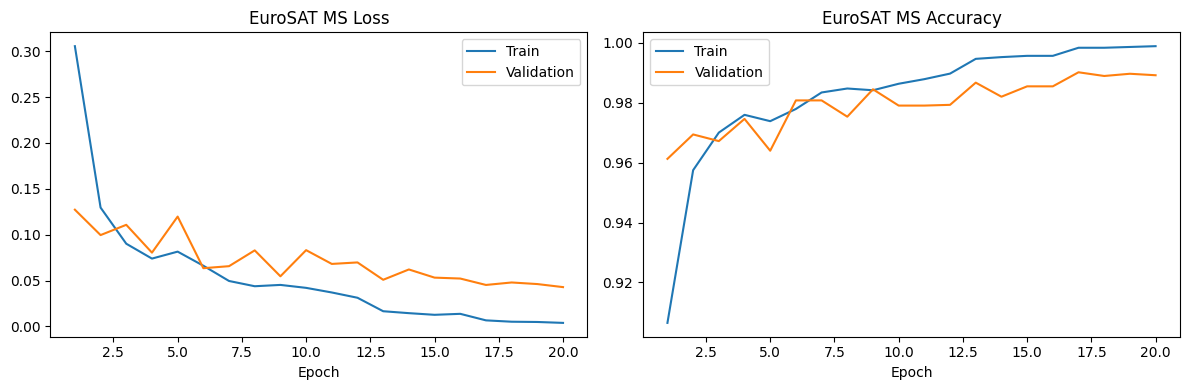

In [49]:
MS_EPOCHS = 20
MS_EARLY_STOP_PATIENCE = 5
MS_CHECKPOINT_PATH = LOCAL_CHECKPOINT_DIR / "best_resnet50_eurosat_multispectral.pth"
MS_HISTORY = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}
MS_BEST_VAL_LOSS = float("inf")
MS_BEST_EPOCH = 0
MS_WAIT = 0
MS_BEST_STATE = None

seed_value = int(globals().get("SEED", 42))
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)
MS_TRAINING_START = time.perf_counter()

for epoch in range(1, MS_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = run_ms_epoch(MS_MODEL, MS_TRAIN_LOADER, training=True)
    val_loss, val_accuracy = run_ms_epoch(MS_MODEL, MS_VAL_LOADER, training=False)
    MS_SCHEDULER.step(val_loss)

    MS_HISTORY["train_loss"].append(train_loss)
    MS_HISTORY["val_loss"].append(val_loss)
    MS_HISTORY["train_accuracy"].append(train_accuracy)
    MS_HISTORY["val_accuracy"].append(val_accuracy)

    if val_loss < MS_BEST_VAL_LOSS:
        MS_BEST_VAL_LOSS = val_loss
        MS_BEST_EPOCH = epoch
        MS_WAIT = 0
        MS_BEST_STATE = {
            key: value.detach().cpu().clone()
            for key, value in MS_MODEL.state_dict().items()
        }
    else:
        MS_WAIT += 1

    current_lr = MS_OPTIMIZER.param_groups[0]["lr"]
    print(
        f"Epoch {epoch:02d}/{MS_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"lr {current_lr:.2e} | {time.perf_counter() - epoch_start:.1f}s"
    )
    if MS_WAIT >= MS_EARLY_STOP_PATIENCE:
        print(f"Early stopping: validation loss did not improve for {MS_EARLY_STOP_PATIENCE} epochs.")
        break

MS_TRAINING_SECONDS = time.perf_counter() - MS_TRAINING_START
if MS_BEST_STATE is None:
    raise RuntimeError("Training did not produce a validation-selected checkpoint.")

MS_MODEL.load_state_dict(MS_BEST_STATE)
ms_saved_checkpoint = {
    "format_version": 2,
    "architecture": "resnet50_multispectral",
    "input_channels": 13,
    "model_state_dict": MS_BEST_STATE,
    "class_names": MS_CLASS_NAMES,
    "class_to_idx": MS_CLASS_TO_IDX,
    "band_order": EUROSAT_MS_BAND_ORDER,
    "normalization_mean": MS_BAND_MEAN.tolist(),
    "normalization_std": MS_BAND_STD.tolist(),
    "image_size": MS_IMAGE_SIZE,
    "split_mode": MS_SPLIT_MODE,
    "train_indices": MS_TRAIN_INDICES.tolist(),
    "validation_indices": MS_VAL_INDICES.tolist(),
    "test_indices": MS_TEST_INDICES.tolist(),
    "best_epoch": MS_BEST_EPOCH,
    "best_validation_loss": MS_BEST_VAL_LOSS,
    "training_seconds": float(MS_TRAINING_SECONDS),
    "dataset": "EuroSAT Multispectral",
    "seed": int(SEED),
}
MS_PERSISTENT_CHECKPOINT_PATH = save_verified_checkpoint(
    ms_saved_checkpoint, MS_CHECKPOINT_PATH
)

print(
    f"Best epoch: {MS_BEST_EPOCH} | best validation loss: {MS_BEST_VAL_LOSS:.4f}"
)
print(f"Training time: {MS_TRAINING_SECONDS:.1f}s")
print(f"Saved checkpoint: {MS_CHECKPOINT_PATH.resolve()}")
print(f"Checkpoint size: {MS_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.2f} MiB")

ms_epochs = range(1, len(MS_HISTORY["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ms_epochs, MS_HISTORY["train_loss"], label="Train")
axes[0].plot(ms_epochs, MS_HISTORY["val_loss"], label="Validation")
axes[0].set(title="EuroSAT MS Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(ms_epochs, MS_HISTORY["train_accuracy"], label="Train")
axes[1].plot(ms_epochs, MS_HISTORY["val_accuracy"], label="Validation")
axes[1].set(title="EuroSAT MS Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


## 51. One-Time Held-Out Test Evaluation

Load the best saved multispectral checkpoint and evaluate the untouched test set once. The model and preprocessing are unchanged from training; all downstream comparisons use these new scores rather than prior-run numbers.


In [50]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

if not MS_CHECKPOINT_PATH.exists():
    raise FileNotFoundError("Run the manual multispectral training cell before test evaluation.")

ms_checkpoint = torch.load(MS_CHECKPOINT_PATH, map_location="cpu", weights_only=True)
if ms_checkpoint["class_names"] != MS_CLASS_NAMES:
    raise ValueError("Checkpoint class mapping differs from the active multispectral dataset.")
if ms_checkpoint["band_order"] != EUROSAT_MS_BAND_ORDER:
    raise ValueError("Checkpoint band order differs from the active multispectral dataset.")

MS_MODEL.load_state_dict(ms_checkpoint["model_state_dict"])
MS_MODEL = MS_MODEL.to(MS_DEVICE).eval()
MS_TEST_LABELS = []
MS_TEST_PREDICTIONS = []

with torch.no_grad():
    for images, labels in MS_TEST_LOADER:
        logits = MS_MODEL(images.to(MS_DEVICE, non_blocking=True))
        predictions = logits.argmax(dim=1).cpu().numpy()
        MS_TEST_PREDICTIONS.extend(predictions.tolist())
        MS_TEST_LABELS.extend(labels.numpy().tolist())

MS_TEST_LABELS = np.asarray(MS_TEST_LABELS, dtype=np.int64)
MS_TEST_PREDICTIONS = np.asarray(MS_TEST_PREDICTIONS, dtype=np.int64)
ms_macro_precision, ms_macro_recall, ms_macro_f1, _ = precision_recall_fscore_support(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    average="macro",
    zero_division=0,
)
MS_TEST_METRICS = {
    "accuracy": float(accuracy_score(MS_TEST_LABELS, MS_TEST_PREDICTIONS)),
    "macro_precision": float(ms_macro_precision),
    "macro_recall": float(ms_macro_recall),
    "macro_f1": float(ms_macro_f1),
    "test_images": int(len(MS_TEST_LABELS)),
}
print(f"Multispectral held-out test accuracy: {MS_TEST_METRICS['accuracy']:.4f}")
print(f"Macro precision: {MS_TEST_METRICS['macro_precision']:.4f}")
print(f"Macro recall:    {MS_TEST_METRICS['macro_recall']:.4f}")
print(f"Macro F1-score:  {MS_TEST_METRICS['macro_f1']:.4f}")
print("Test images:", MS_TEST_METRICS["test_images"])


Multispectral held-out test accuracy: 0.9869
Macro precision: 0.9863
Macro recall:    0.9864
Macro F1-score:  0.9863
Test images: 4050


## 52. Classification Report and Confusion Matrix

The table reports per-class precision, recall, F1, and support. The confusion matrix uses true classes as rows and predicted classes as columns.

Expected output: per-class test performance and a 10×10 confusion matrix.


                      precision    recall  f1-score   support

          AnnualCrop     0.9842    0.9667    0.9753       450
              Forest     0.9933    0.9933    0.9933       450
HerbaceousVegetation     0.9845    0.9889    0.9867       450
             Highway     0.9840    0.9840    0.9840       375
          Industrial     0.9973    0.9893    0.9933       375
             Pasture     0.9766    0.9733    0.9750       300
       PermanentCrop     0.9633    0.9787    0.9709       375
         Residential     0.9934    1.0000    0.9967       450
               River     0.9867    0.9893    0.9880       375
             SeaLake     1.0000    1.0000    1.0000       450

            accuracy                         0.9869      4050
           macro avg     0.9863    0.9864    0.9863      4050
        weighted avg     0.9869    0.9869    0.9869      4050



,precision,recall,f1-score,support
AnnualCrop,0.9842,0.9667,0.9753,450.0
Forest,0.9933,0.9933,0.9933,450.0
HerbaceousVegetation,0.9845,0.9889,0.9867,450.0
Highway,0.9840,0.9840,0.9840,375.0
Industrial,0.9973,0.9893,0.9933,375.0
Pasture,0.9766,0.9733,0.9750,300.0
PermanentCrop,0.9633,0.9787,0.9709,375.0
Residential,0.9934,1.0000,0.9967,450.0
River,0.9867,0.9893,0.9880,375.0
SeaLake,1.0000,1.0000,1.0000,450.0


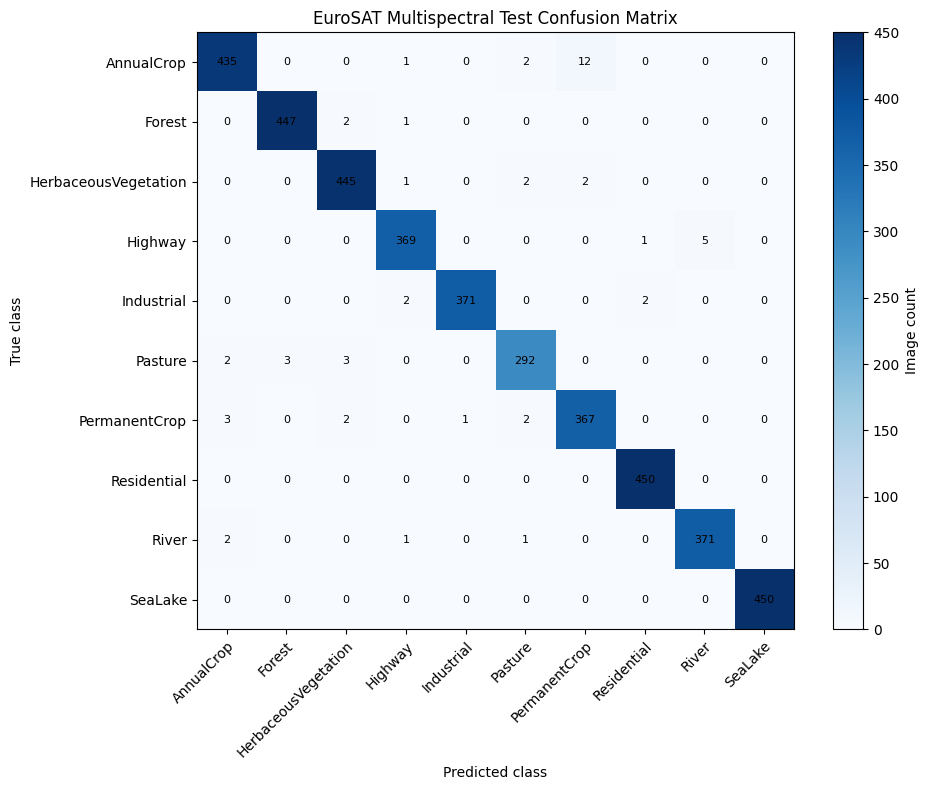

In [51]:
from sklearn.metrics import classification_report, confusion_matrix

MS_CLASSIFICATION_REPORT = classification_report(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    target_names=MS_CLASS_NAMES,
    output_dict=True,
    digits=4,
    zero_division=0,
)
print(classification_report(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    target_names=MS_CLASS_NAMES,
    digits=4,
    zero_division=0,
))

MS_PER_CLASS_REPORT = pd.DataFrame(
    MS_CLASSIFICATION_REPORT
).T.loc[MS_CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
display(MS_PER_CLASS_REPORT.round(4))

MS_CONFUSION = confusion_matrix(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
)
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(MS_CONFUSION, cmap="Blues")
ax.set(
    xticks=np.arange(MS_NUM_CLASSES),
    yticks=np.arange(MS_NUM_CLASSES),
    xticklabels=MS_CLASS_NAMES,
    yticklabels=MS_CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Multispectral Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(MS_NUM_CLASSES):
    for column in range(MS_NUM_CLASSES):
        ax.text(column, row, str(MS_CONFUSION[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()


## 53. RGB vs. Multispectral Comparison

This comparison combines the already recorded RGB test results with the actual multispectral evaluation after you run the new training/evaluation cells. Training time and saved-checkpoint size are read from the run/checkpoint when available. ResNet50 RGB time is estimated by summing its displayed one-decimal epoch durations (about 102.3 seconds); EfficientNet-B0 time is taken from its training timer.

If filename/class keys matched, all three models share the same underlying RGB test samples and split. Otherwise the MS result comes from its own reproducible stratified split, so test metrics should be read as separate evaluations. RGB uses three visible channels; the MS model uses all 13 Sentinel-2 bands and training-only band statistics. The MS metrics remain blank until the new model is actually trained and evaluated.

Expected output: accuracy, macro precision/recall/F1, training time, checkpoint size, test sample count, and a comparison chart.


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB),Test images
0,ResNet50 RGB,0.9790,0.9785,0.9789,0.9786,746.4859,90.0542,4050
1,EfficientNet-B0 RGB,0.9704,0.9690,0.9698,0.9693,956.0042,15.6161,4050
2,ResNet50 Multispectral (13 bands),0.9869,0.9863,0.9864,0.9863,5017.3211,90.2559,4050


MS split mode: same RGB samples and same RGB split (filename/class keys matched)
ResNet50 RGB actual measured training time: 746.5s.


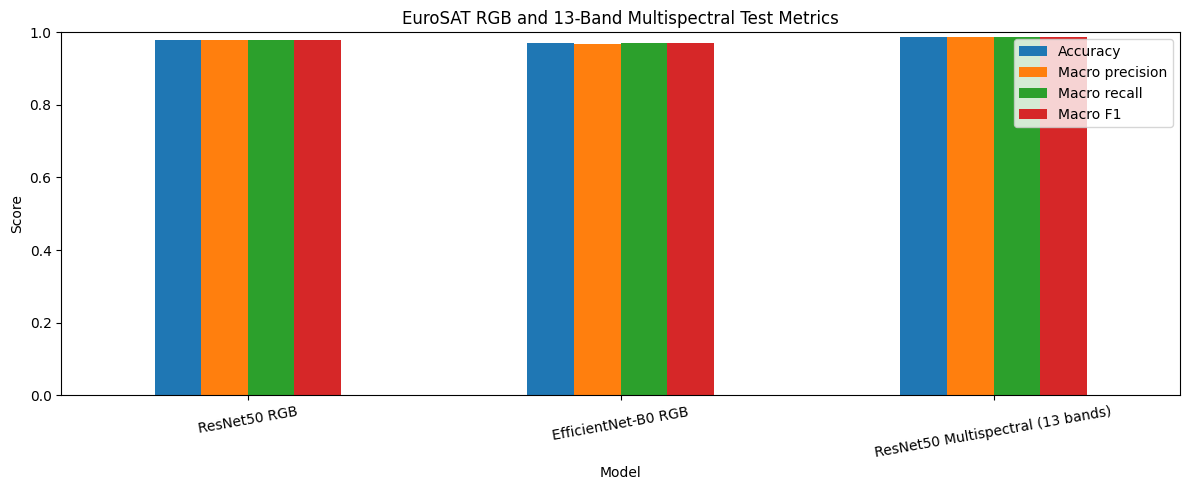

In [52]:
from sklearn.metrics import accuracy_score, classification_report

def checkpoint_size_mib(path):
    path = Path(path)
    return path.stat().st_size / (1024 ** 2) if path.exists() else np.nan

comparison_rows = []
resnet_rgb_training_seconds = float(RGB_TRAINING_SECONDS)
if "all_labels" in globals() and "all_predictions" in globals():
    resnet_report = classification_report(
        all_labels, all_predictions, labels=np.arange(len(class_names)),
        target_names=class_names, output_dict=True, zero_division=0
    )
    resnet_path = Path(globals().get("MODEL_PATH", "best_resnet50_eurosat.pth"))
    comparison_rows.append({
        "Model": "ResNet50 RGB",
        "Accuracy": accuracy_score(all_labels, all_predictions),
        "Macro precision": resnet_report["macro avg"]["precision"],
        "Macro recall": resnet_report["macro avg"]["recall"],
        "Macro F1": resnet_report["macro avg"]["f1-score"],
        "Training time (s)": resnet_rgb_training_seconds,
        "Checkpoint size (MiB)": checkpoint_size_mib(resnet_path),
        "Test images": len(all_labels),
    })

if "efficientnet_test_labels" in globals() and "efficientnet_test_predictions" in globals():
    efficientnet_report_for_ms_comparison = classification_report(
        efficientnet_test_labels,
        efficientnet_test_predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    efficientnet_path = Path(
        globals().get("EFFICIENTNET_MODEL_PATH", "best_efficientnet_b0_eurosat.pth")
    )
    comparison_rows.append({
        "Model": "EfficientNet-B0 RGB",
        "Accuracy": accuracy_score(efficientnet_test_labels, efficientnet_test_predictions),
        "Macro precision": efficientnet_report_for_ms_comparison["macro avg"]["precision"],
        "Macro recall": efficientnet_report_for_ms_comparison["macro avg"]["recall"],
        "Macro F1": efficientnet_report_for_ms_comparison["macro avg"]["f1-score"],
        "Training time (s)": globals().get("efficientnet_training_seconds", np.nan),
        "Checkpoint size (MiB)": checkpoint_size_mib(efficientnet_path),
        "Test images": len(efficientnet_test_labels),
    })

if "MS_TEST_METRICS" in globals():
    comparison_rows.append({
        "Model": "ResNet50 Multispectral (13 bands)",
        "Accuracy": MS_TEST_METRICS["accuracy"],
        "Macro precision": MS_TEST_METRICS["macro_precision"],
        "Macro recall": MS_TEST_METRICS["macro_recall"],
        "Macro F1": MS_TEST_METRICS["macro_f1"],
        "Training time (s)": globals().get("MS_TRAINING_SECONDS", np.nan),
        "Checkpoint size (MiB)": checkpoint_size_mib(
            globals().get("MS_CHECKPOINT_PATH", "best_resnet50_eurosat_multispectral.pth")
        ),
        "Test images": MS_TEST_METRICS["test_images"],
    })
else:
    comparison_rows.append({
        "Model": "ResNet50 Multispectral (13 bands)",
        "Accuracy": np.nan,
        "Macro precision": np.nan,
        "Macro recall": np.nan,
        "Macro F1": np.nan,
        "Training time (s)": np.nan,
        "Checkpoint size (MiB)": checkpoint_size_mib(
            "best_resnet50_eurosat_multispectral.pth"
        ),
        "Test images": len(MS_TEST_INDICES) if "MS_TEST_INDICES" in globals() else np.nan,
    })

MS_RGB_COMPARISON = pd.DataFrame(comparison_rows)
display(MS_RGB_COMPARISON.round(4))
print("MS split mode:", globals().get("MS_SPLIT_MODE", "not prepared"))
if np.isfinite(resnet_rgb_training_seconds):
    print(f"ResNet50 RGB actual measured training time: {resnet_rgb_training_seconds:.1f}s.")
if "MS_TEST_METRICS" not in globals():
    print("MS metrics are intentionally unreported until manual training and held-out evaluation.")

metric_columns = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
ax = MS_RGB_COMPARISON.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 5), ylim=(0.0, 1.0)
)
ax.set_title("EuroSAT RGB and 13-Band Multispectral Test Metrics")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()


## 54. Multispectral Pipeline Notes

- RGB training uses 3-channel EuroSAT JPEGs, ImageNet normalization, and 224×224 inputs; multispectral training reads 13-band GeoTIFFs and uses **training-only per-band statistics**.
- **The exact same RGB train/validation/test membership is required** for the MS comparison, validated via `(class, filename stem)` and labels.
- Band descriptions are checked and reordered where provided. Unnamed EuroSAT TIFF bands are interpreted in the documented order `B01 … B12, B8A`; external Sentinel-2 files require a **verified compatible order and values**.
- Pixel validity and normalization are preserved between training and future 13-band inference. Class metadata and processing parameters are saved inside the checkpoint.
- The test split is image-stratified, **not geographically independent**. External geographic evaluation (e.g., Egypt) is optional future work and is not claimed here.


## 55. Joint Error Analysis: ResNet50 RGB and Multispectral

This stage performs final analysis on the existing held-out test split only. It does not train, fine-tune, or update model weights. It loads the saved ResNet50 RGB and 13-band checkpoints when available, and otherwise uses the already-loaded, evaluated models. If a model, checkpoint, or test loader is unavailable, that model is skipped with a clear message.

We compare class-wise precision, recall, and F1, inspect both confusion matrices, rank the largest true-to-predicted confusions, and display representative mistakes with their true and predicted labels. For multispectral images, the displayed picture is a B04/B03/B02 true-color preview; the classifier itself receives all 13 bands.


In [53]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from torchvision import models

ANALYSIS_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ANALYSIS_CLASS_NAMES = list(
    globals().get("class_names", globals().get("MS_CLASS_NAMES", []))
)
if not ANALYSIS_CLASS_NAMES:
    raise RuntimeError("Class names are unavailable. Run the notebook's data setup cells first.")
ANALYSIS_NUM_CLASSES = len(ANALYSIS_CLASS_NAMES)

ANALYSIS_MODELS = {}
ANALYSIS_MODEL_NOTES = {}

def _build_resnet_from_checkpoint(checkpoint_path, expected_channels):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    state_dict = checkpoint.get("model_state_dict", checkpoint)
    checkpoint_classes = checkpoint.get("class_names", ANALYSIS_CLASS_NAMES)
    if list(checkpoint_classes) != ANALYSIS_CLASS_NAMES:
        raise ValueError("Checkpoint class order does not match the notebook class order.")
    if "conv1.weight" not in state_dict:
        raise KeyError("Checkpoint is missing the ResNet stem weights.")
    if int(state_dict["conv1.weight"].shape[1]) != expected_channels:
        raise ValueError(
            f"Checkpoint expects {state_dict['conv1.weight'].shape[1]} input channels; "
            f"expected {expected_channels}."
        )

    resnet = models.resnet50(weights=None)
    if expected_channels != 3:
        old_stem = resnet.conv1
        resnet.conv1 = nn.Conv2d(
            expected_channels,
            old_stem.out_channels,
            kernel_size=old_stem.kernel_size,
            stride=old_stem.stride,
            padding=old_stem.padding,
            bias=False,
        )
    resnet.fc = nn.Linear(resnet.fc.in_features, ANALYSIS_NUM_CLASSES)
    resnet.load_state_dict(state_dict)
    return resnet

def _load_analysis_model(kind, expected_channels):
    if kind == "rgb":
        path = Path(globals().get("MODEL_PATH", "best_resnet50_eurosat.pth"))
        object_names = ("loaded_model", "model")
        best_state_name = "best_model_state"
    else:
        path = Path(
            globals().get(
                "MS_CHECKPOINT_PATH",
                "best_resnet50_eurosat_multispectral.pth",
            )
        )
        object_names = ("MS_MODEL",)
        best_state_name = "MS_BEST_STATE"

    checkpoint_error = None
    if path.exists():
        try:
            model_instance = _build_resnet_from_checkpoint(path, expected_channels)
            ANALYSIS_MODEL_NOTES[kind] = f"Loaded checkpoint: {path}"
            return model_instance.to(ANALYSIS_DEVICE).eval()
        except Exception as error:
            checkpoint_error = f"Could not load {path}: {type(error).__name__}: {error}"

    # If the file is unavailable, reuse an evaluated model already held in memory.
    for object_name in object_names:
        source_model = globals().get(object_name)
        if not isinstance(source_model, nn.Module):
            continue
        if int(source_model.conv1.in_channels) != expected_channels:
            continue

        best_state = globals().get(best_state_name)
        is_known_trained = (
            kind == "rgb"
            and (object_name == "loaded_model" or best_state is not None)
        ) or (
            kind == "multispectral"
            and (
                best_state is not None
                or "MS_TEST_PREDICTIONS" in globals()
                or "MS_TEST_METRICS" in globals()
            )
        )
        if not is_known_trained:
            continue

        model_instance = copy.deepcopy(source_model)
        if best_state is not None:
            model_instance.load_state_dict(best_state)
        ANALYSIS_MODEL_NOTES[kind] = (
            f"Reused already-loaded model: {object_name}"
            + (f"; checkpoint note: {checkpoint_error}" if checkpoint_error else "")
        )
        return model_instance.to(ANALYSIS_DEVICE).eval()

    if checkpoint_error:
        ANALYSIS_MODEL_NOTES[kind] = checkpoint_error
    else:
        ANALYSIS_MODEL_NOTES[kind] = (
            f"No checkpoint or evaluated in-memory model found for {kind}."
        )
    return None

ANALYSIS_MODELS["ResNet50 RGB"] = _load_analysis_model("rgb", expected_channels=3)
ANALYSIS_MODELS["ResNet50 Multispectral"] = _load_analysis_model(
    "multispectral", expected_channels=13
)

for model_name, model_instance in ANALYSIS_MODELS.items():
    if model_instance is None:
        print(f"{model_name}: skipped. {ANALYSIS_MODEL_NOTES['rgb' if model_name.endswith('RGB') else 'multispectral']}")
    else:
        expected_channels = 3 if model_name.endswith("RGB") else 13
        assert model_instance.conv1.in_channels == expected_channels
        assert model_instance.fc.out_features == ANALYSIS_NUM_CLASSES
        print(
            f"{model_name}: ready | input channels={model_instance.conv1.in_channels} | "
            f"classes={model_instance.fc.out_features} | device={ANALYSIS_DEVICE}"
        )
        print("  " + ANALYSIS_MODEL_NOTES["rgb" if model_name.endswith("RGB") else "multispectral"])

def _predict_test_loader(model_instance, loader, expected_channels):
    true_labels = []
    predicted_labels = []
    probabilities = []
    model_instance.eval()
    with torch.inference_mode():
        for images, labels in loader:
            if images.ndim != 4 or images.shape[1] != expected_channels:
                raise ValueError(
                    f"Expected input shape (batch, {expected_channels}, height, width); "
                    f"received {tuple(images.shape)}."
                )
            logits = model_instance(images.to(ANALYSIS_DEVICE, non_blocking=True))
            batch_probabilities = torch.softmax(logits, dim=1).cpu().numpy()
            probabilities.extend(batch_probabilities)
            predicted_labels.extend(batch_probabilities.argmax(axis=1).tolist())
            true_labels.extend(labels.cpu().numpy().tolist())
    return (
        np.asarray(true_labels, dtype=np.int64),
        np.asarray(predicted_labels, dtype=np.int64),
        np.asarray(probabilities, dtype=np.float32),
    )

ANALYSIS_SPECS = {
    "ResNet50 RGB": {
        "model_key": "ResNet50 RGB",
        "loader_name": "test_loader",
        "channels": 3,
        "cached_true": "all_labels",
        "cached_pred": "all_predictions",
    },
    "ResNet50 Multispectral": {
        "model_key": "ResNet50 Multispectral",
        "loader_name": "MS_TEST_LOADER",
        "channels": 13,
        "cached_true": "MS_TEST_LABELS",
        "cached_pred": "MS_TEST_PREDICTIONS",
    },
}

ERROR_ANALYSIS_RESULTS = {}
for model_name, spec in ANALYSIS_SPECS.items():
    model_instance = ANALYSIS_MODELS[spec["model_key"]]
    loader = globals().get(spec["loader_name"])
    if model_instance is not None and loader is not None:
        try:
            y_true, y_pred, y_prob = _predict_test_loader(
                model_instance, loader, spec["channels"]
            )
            ERROR_ANALYSIS_RESULTS[model_name] = {
                "y_true": y_true,
                "y_pred": y_pred,
                "probabilities": y_prob,
            }
            print(
                f"{model_name}: analyzed {len(y_true):,} held-out test images "
                f"using {spec['channels']} input channels."
            )
            continue
        except Exception as error:
            print(
                f"{model_name}: test-loader inference unavailable "
                f"({type(error).__name__}: {error})."
            )

    cached_true = globals().get(spec["cached_true"])
    cached_pred = globals().get(spec["cached_pred"])
    if cached_true is not None and cached_pred is not None:
        y_true = np.asarray(cached_true, dtype=np.int64)
        y_pred = np.asarray(cached_pred, dtype=np.int64)
        if len(y_true) == len(y_pred):
            ERROR_ANALYSIS_RESULTS[model_name] = {
                "y_true": y_true,
                "y_pred": y_pred,
                "probabilities": None,
            }
            print(f"{model_name}: using its existing cached test predictions.")
            continue

    reason = ANALYSIS_MODEL_NOTES[
        "rgb" if model_name.endswith("RGB") else "multispectral"
    ]
    print(
        f"{model_name}: skipped because its test data/predictions are unavailable. "
        f"{reason} Upload or restore the saved checkpoint and run the existing "
        "test-data preparation/evaluation cells; no training is required."
    )

if not ERROR_ANALYSIS_RESULTS:
    print(
        "No error analysis was run. Restore the existing model checkpoints and "
        "test loaders, then rerun these analysis cells."
    )


ResNet50 RGB: ready | input channels=3 | classes=10 | device=cuda
  Loaded checkpoint: /content/checkpoints/run_20261121_003103_UTC/best_resnet50_eurosat.pth
ResNet50 Multispectral: ready | input channels=13 | classes=10 | device=cuda
  Loaded checkpoint: /content/checkpoints/run_20261121_003103_UTC/best_resnet50_eurosat_multispectral.pth
ResNet50 RGB: analyzed 4,050 held-out test images using 3 input channels.
ResNet50 Multispectral: analyzed 4,050 held-out test images using 13 input channels.


Held-out test error summary:


,Model,Test images,Incorrect,Accuracy,Macro precision,Macro recall,Macro F1
0,ResNet50 RGB,4050,85,0.9790,0.9785,0.9789,0.9786
1,ResNet50 Multispectral,4050,53,0.9869,0.9863,0.9864,0.9863


Per-class Precision, Recall, and F1:


,Class,ResNet50 RGB precision,ResNet50 RGB recall,ResNet50 RGB F1,ResNet50 Multispectral precision,ResNet50 Multispectral recall,ResNet50 Multispectral F1,F1 delta (MS - RGB)
0,AnnualCrop,0.9796,0.9600,0.9697,0.9842,0.9667,0.9753,0.0056
1,Forest,0.9889,0.9933,0.9911,0.9933,0.9933,0.9933,0.0022
2,HerbaceousVegetation,0.9667,0.9667,0.9667,0.9845,0.9889,0.9867,0.0200
3,Highway,0.9587,0.9893,0.9738,0.9840,0.9840,0.9840,0.0102
4,Industrial,0.9919,0.9840,0.9880,0.9973,0.9893,0.9933,0.0054
5,Pasture,0.9767,0.9767,0.9767,0.9766,0.9733,0.9750,-0.0017
6,PermanentCrop,0.9449,0.9600,0.9524,0.9633,0.9787,0.9709,0.0185
7,Residential,0.9912,0.9956,0.9933,0.9934,1.0000,0.9967,0.0033
8,River,0.9866,0.9787,0.9826,0.9867,0.9893,0.9880,0.0054
9,SeaLake,1.0000,0.9844,0.9922,1.0000,1.0000,1.0000,0.0078


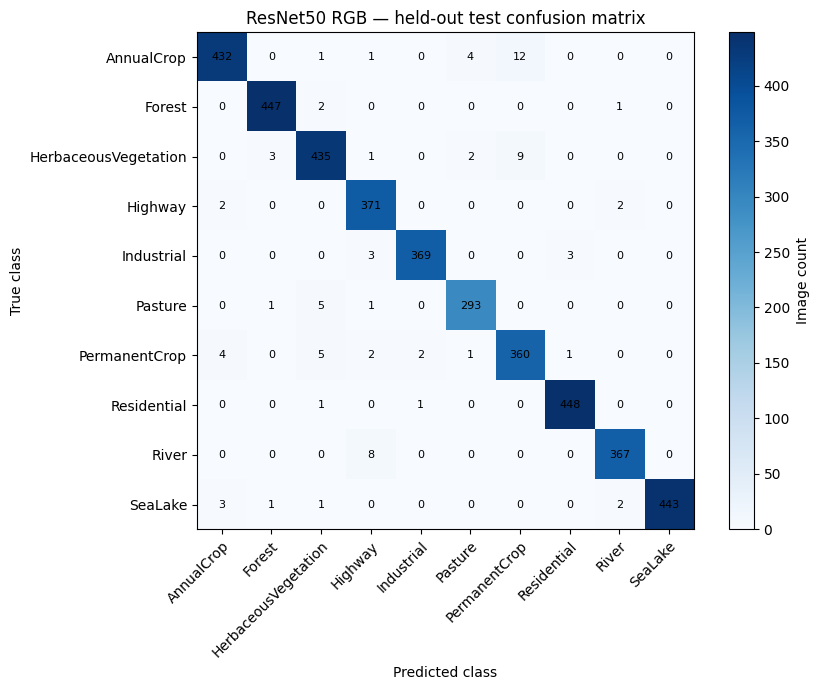

ResNet50 RGB: largest directed confusion pairs


,True class,Predicted class,Count
0,AnnualCrop,PermanentCrop,12
1,HerbaceousVegetation,PermanentCrop,9
2,River,Highway,8
3,Pasture,HerbaceousVegetation,5
4,PermanentCrop,HerbaceousVegetation,5
5,AnnualCrop,Pasture,4
6,PermanentCrop,AnnualCrop,4
7,Industrial,Residential,3


Most involved class in off-diagonal errors: PermanentCrop (36 error counts across its row/column).
Lowest class-wise F1: PermanentCrop.


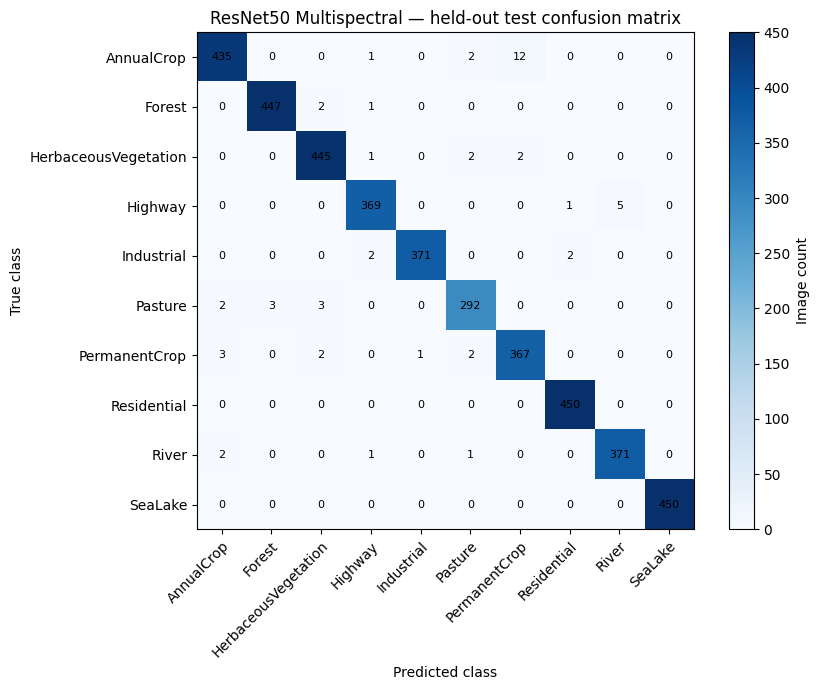

ResNet50 Multispectral: largest directed confusion pairs


,True class,Predicted class,Count
0,AnnualCrop,PermanentCrop,12
1,Highway,River,5
2,Pasture,HerbaceousVegetation,3
3,PermanentCrop,AnnualCrop,3
4,Pasture,Forest,3
5,AnnualCrop,Pasture,2
6,River,AnnualCrop,2
7,Pasture,AnnualCrop,2


Most involved class in off-diagonal errors: AnnualCrop (22 error counts across its row/column).
Lowest class-wise F1: PermanentCrop.


In [54]:
ERROR_ANALYSIS_SUMMARY_ROWS = []
ERROR_ANALYSIS_REPORTS = {}
ERROR_ANALYSIS_CONFUSIONS = {}

for model_name, result in ERROR_ANALYSIS_RESULTS.items():
    y_true = result["y_true"]
    y_pred = result["y_pred"]
    report_dict = classification_report(
        y_true,
        y_pred,
        labels=np.arange(ANALYSIS_NUM_CLASSES),
        target_names=ANALYSIS_CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(ANALYSIS_NUM_CLASSES),
    )
    ERROR_ANALYSIS_REPORTS[model_name] = report_dict
    ERROR_ANALYSIS_CONFUSIONS[model_name] = matrix
    ERROR_ANALYSIS_SUMMARY_ROWS.append({
        "Model": model_name,
        "Test images": len(y_true),
        "Incorrect": int(np.count_nonzero(y_true != y_pred)),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": report_dict["macro avg"]["precision"],
        "Macro recall": report_dict["macro avg"]["recall"],
        "Macro F1": report_dict["macro avg"]["f1-score"],
    })

print("Held-out test error summary:")
display(pd.DataFrame(ERROR_ANALYSIS_SUMMARY_ROWS).round(4))

classwise_comparison = pd.DataFrame({"Class": ANALYSIS_CLASS_NAMES})
for model_name, report_dict in ERROR_ANALYSIS_REPORTS.items():
    classwise_comparison[f"{model_name} precision"] = [
        report_dict[name]["precision"] for name in ANALYSIS_CLASS_NAMES
    ]
    classwise_comparison[f"{model_name} recall"] = [
        report_dict[name]["recall"] for name in ANALYSIS_CLASS_NAMES
    ]
    classwise_comparison[f"{model_name} F1"] = [
        report_dict[name]["f1-score"] for name in ANALYSIS_CLASS_NAMES
    ]

if {"ResNet50 RGB F1", "ResNet50 Multispectral F1"}.issubset(classwise_comparison.columns):
    classwise_comparison["F1 delta (MS - RGB)"] = (
        classwise_comparison["ResNet50 Multispectral F1"]
        - classwise_comparison["ResNet50 RGB F1"]
    )
print("Per-class Precision, Recall, and F1:")
display(classwise_comparison.round(4))

def _rank_confusion_pairs(matrix, class_names, limit=8):
    pairs = []
    for true_index in range(len(class_names)):
        for predicted_index in range(len(class_names)):
            if true_index == predicted_index:
                continue
            count = int(matrix[true_index, predicted_index])
            if count:
                pairs.append({
                    "True class": class_names[true_index],
                    "Predicted class": class_names[predicted_index],
                    "Count": count,
                })
    return pd.DataFrame(pairs).sort_values(
        "Count", ascending=False
    ).head(limit).reset_index(drop=True) if pairs else pd.DataFrame(
        columns=["True class", "Predicted class", "Count"]
    )

for model_name, matrix in ERROR_ANALYSIS_CONFUSIONS.items():
    fig, ax = plt.subplots(figsize=(9, 7))
    image_plot = ax.imshow(matrix, cmap="Blues")
    ax.set(
        xticks=np.arange(ANALYSIS_NUM_CLASSES),
        yticks=np.arange(ANALYSIS_NUM_CLASSES),
        xticklabels=ANALYSIS_CLASS_NAMES,
        yticklabels=ANALYSIS_CLASS_NAMES,
        xlabel="Predicted class",
        ylabel="True class",
        title=f"{model_name} — held-out test confusion matrix",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for row in range(ANALYSIS_NUM_CLASSES):
        for column in range(ANALYSIS_NUM_CLASSES):
            ax.text(column, row, str(matrix[row, column]),
                    ha="center", va="center", fontsize=8)
    fig.colorbar(image_plot, ax=ax, label="Image count")
    plt.tight_layout()
    plt.show()

    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pair_table = _rank_confusion_pairs(matrix, ANALYSIS_CLASS_NAMES)
    class_involvement = off_diagonal.sum(axis=0) + off_diagonal.sum(axis=1)
    most_involved_index = int(class_involvement.argmax())
    worst_f1_class = min(
        ANALYSIS_CLASS_NAMES,
        key=lambda name: classwise_comparison.loc[
            classwise_comparison["Class"] == name,
            f"{model_name} F1",
        ].iloc[0],
    ) if f"{model_name} F1" in classwise_comparison.columns else "unavailable"

    print(f"{model_name}: largest directed confusion pairs")
    display(pair_table)
    print(
        f"Most involved class in off-diagonal errors: "
        f"{ANALYSIS_CLASS_NAMES[most_involved_index]} "
        f"({int(class_involvement[most_involved_index])} error counts across its row/column)."
    )
    print(f"Lowest class-wise F1: {worst_f1_class}.")


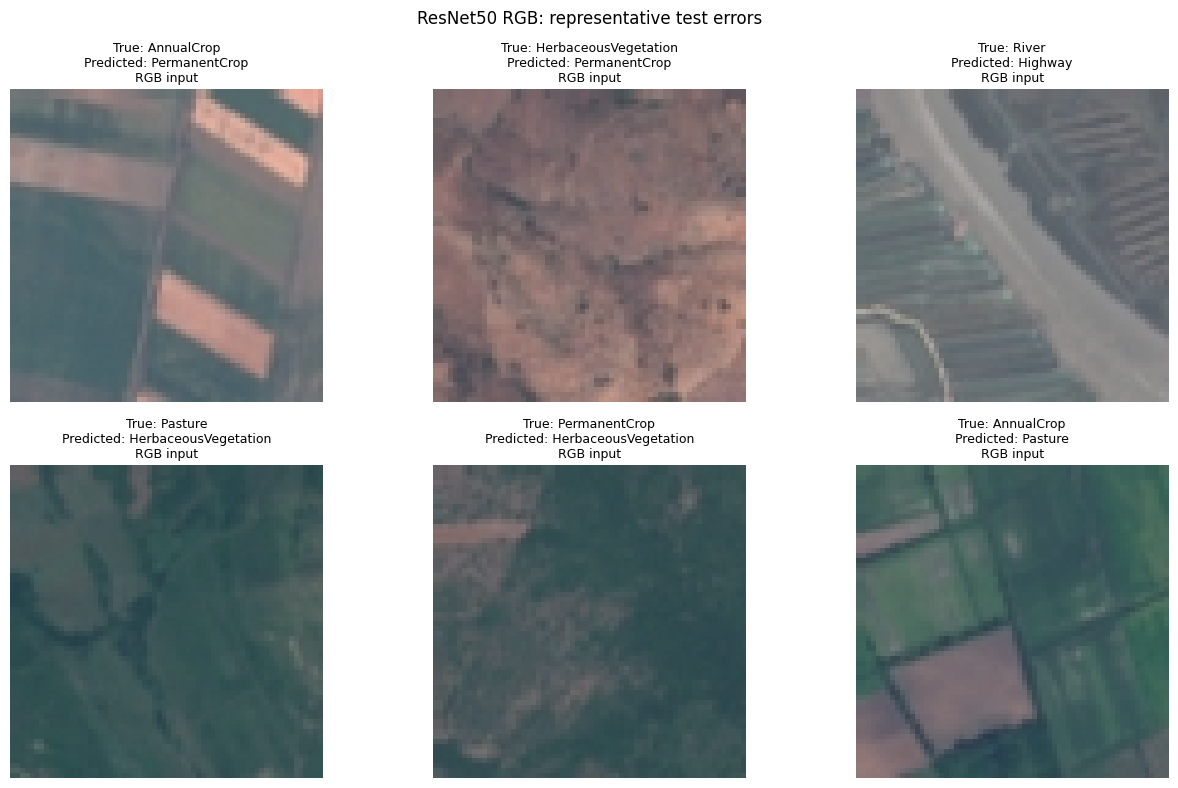

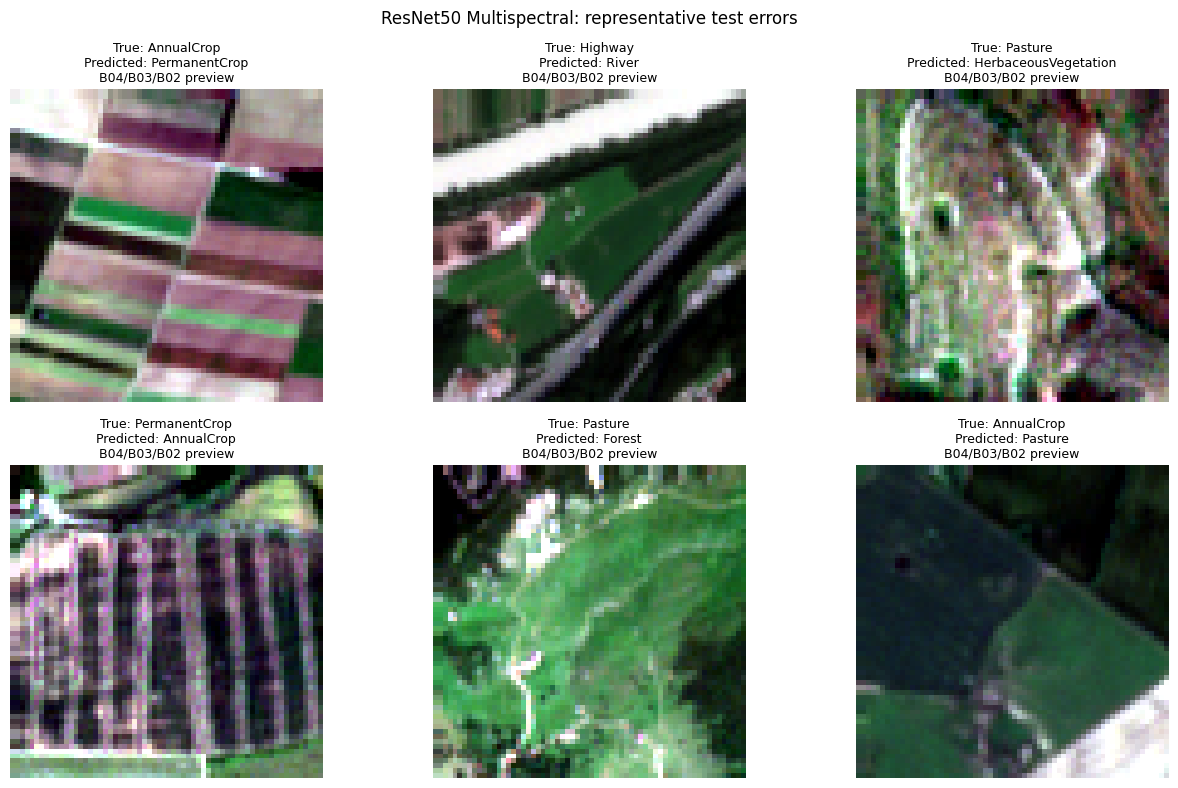

In [55]:
def _rgb_test_preview(test_position):
    if "test_set" in globals() and "dataset" in globals():
        source_index = int(test_set.indices[int(test_position)])
        image, _ = dataset[source_index]
        return np.asarray(image.convert("RGB") if hasattr(image, "convert") else image)
    if "test_set" in globals():
        tensor, _ = test_set[int(test_position)]
        image = tensor.detach().cpu().float().numpy()
        mean = np.asarray(globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))[:, None, None]
        std = np.asarray(globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))[:, None, None]
        return np.clip(((image * std + mean).transpose(1, 2, 0)), 0, 1)
    raise RuntimeError("RGB test images are unavailable.")

def _multispectral_true_color_preview(record_index):
    if "MS_RECORDS" not in globals() or "read_eurosat_ms" not in globals():
        raise RuntimeError("Multispectral TIFF records or Rasterio loader are unavailable.")
    data, nodata_values, masks = read_eurosat_ms(
        MS_RECORDS[int(record_index)]["path"]
    )
    valid_pixels = valid_ms_pixels(data, nodata_values, masks)
    # Canonical channel order: B04, B03, B02 is the RGB display composite.
    selected = data[[3, 2, 1]].astype(np.float32)
    selected_valid = np.all(valid_pixels[[3, 2, 1]], axis=0)
    preview = np.zeros((*selected.shape[1:], 3), dtype=np.float32)
    for display_channel in range(3):
        channel = selected[display_channel]
        values = channel[selected_valid & np.isfinite(channel)]
        if values.size:
            low, high = np.percentile(values, [2, 98])
            if high > low:
                preview[..., display_channel] = np.clip(
                    (channel - low) / (high - low), 0, 1
                )
    return preview

def _representative_error_positions(result, maximum=6):
    y_true = result["y_true"]
    y_pred = result["y_pred"]
    wrong_positions = np.flatnonzero(y_true != y_pred)
    if wrong_positions.size == 0:
        return []

    matrix = confusion_matrix(
        y_true, y_pred, labels=np.arange(ANALYSIS_NUM_CLASSES)
    )
    pair_table = _rank_confusion_pairs(
        matrix, ANALYSIS_CLASS_NAMES, limit=maximum
    )
    selected = []
    for _, pair in pair_table.iterrows():
        true_index = ANALYSIS_CLASS_NAMES.index(pair["True class"])
        pred_index = ANALYSIS_CLASS_NAMES.index(pair["Predicted class"])
        candidates = np.flatnonzero((y_true == true_index) & (y_pred == pred_index))
        if candidates.size:
            selected.append(int(candidates[0]))
        if len(selected) >= maximum:
            break
    for position in wrong_positions:
        if int(position) not in selected:
            selected.append(int(position))
        if len(selected) >= maximum:
            break
    return selected

for model_name, result in ERROR_ANALYSIS_RESULTS.items():
    error_positions = _representative_error_positions(result, maximum=6)
    if not error_positions:
        print(f"{model_name}: no misclassified images on this test split.")
        continue

    is_multispectral = model_name.endswith("Multispectral")
    try:
        fig, axes = plt.subplots(2, 3, figsize=(13, 8))
        axes = axes.ravel()
        for axis, position in zip(axes, error_positions):
            true_index = int(result["y_true"][position])
            pred_index = int(result["y_pred"][position])
            if is_multispectral:
                record_index = int(MS_TEST_SET.indices[position])
                image = _multispectral_true_color_preview(record_index)
                source_note = "B04/B03/B02 preview"
            else:
                image = _rgb_test_preview(position)
                source_note = "RGB input"

            axis.imshow(image)
            axis.set_title(
                f"True: {ANALYSIS_CLASS_NAMES[true_index]}\n"
                f"Predicted: {ANALYSIS_CLASS_NAMES[pred_index]}\n"
                f"{source_note}",
                fontsize=9,
            )
            axis.axis("off")
        for axis in axes[len(error_positions):]:
            axis.axis("off")
        fig.suptitle(f"{model_name}: representative test errors")
        plt.tight_layout()
        plt.show()
    except Exception as error:
        print(
            f"{model_name}: prediction analysis is available, but image display "
            f"was skipped ({type(error).__name__}: {error})."
        )


## 56. Grad-CAM for RGB and 13-Band ResNet50

Grad-CAM highlights spatial regions whose last-block activations support the model's predicted class. For a correct example the target is the correct prediction; for a mistake the target is the model's incorrect predicted class. Warm colors indicate stronger positive contribution to that chosen score, not a causal explanation.

For each model this stage selects one correct and one incorrect held-out test image when both are available. It shows the input preview, heatmap, and overlay. The multispectral heatmap is computed from all 13 channels; the displayed B04/B03/B02 composite is only a human-readable visual reference.

Expected output: side-by-side Grad-CAM visualizations for correctly and incorrectly classified test images. No training or parameter updates occur.


In [56]:
import torch.nn.functional as F

def generate_analysis_gradcam(model_instance, image_tensor, expected_channels, target_class=None):
    if image_tensor.ndim == 3:
        image_tensor = image_tensor.unsqueeze(0)
    if image_tensor.ndim != 4 or image_tensor.shape[1] != expected_channels:
        raise ValueError(
            f"Grad-CAM expected (batch, {expected_channels}, H, W), "
            f"received {tuple(image_tensor.shape)}."
        )

    model_instance.eval()
    image_tensor = image_tensor.to(ANALYSIS_DEVICE)
    activations = {}
    gradients = {}
    target_layer = model_instance.layer4[-1]

    def _capture_activation(module, inputs, output):
        activations["value"] = output
        output.register_hook(lambda gradient: gradients.__setitem__("value", gradient))

    hook_handle = target_layer.register_forward_hook(_capture_activation)
    model_instance.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits = model_instance(image_tensor)
            predicted_index = int(logits.argmax(dim=1)[0].item())
            cam_target = predicted_index if target_class is None else int(target_class)
            logits[0, cam_target].backward()

        if "value" not in activations or "value" not in gradients:
            raise RuntimeError("Grad-CAM did not capture the target-layer activations/gradients.")

        activation = activations["value"].detach()
        gradient = gradients["value"].detach()
        channel_weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((channel_weights * activation).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=tuple(image_tensor.shape[-2:]),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        cam -= cam.min()
        maximum = cam.max()
        if float(maximum.item()) > 0:
            cam /= maximum
        probabilities = torch.softmax(logits.detach(), dim=1)[0]
        return (
            cam.cpu().numpy(),
            predicted_index,
            float(probabilities[predicted_index].item()),
            cam_target,
        )
    finally:
        hook_handle.remove()
        model_instance.zero_grad(set_to_none=True)

print("Grad-CAM helper ready. Target layer: ResNet50 layer4[-1].")


Grad-CAM helper ready. Target layer: ResNet50 layer4[-1].


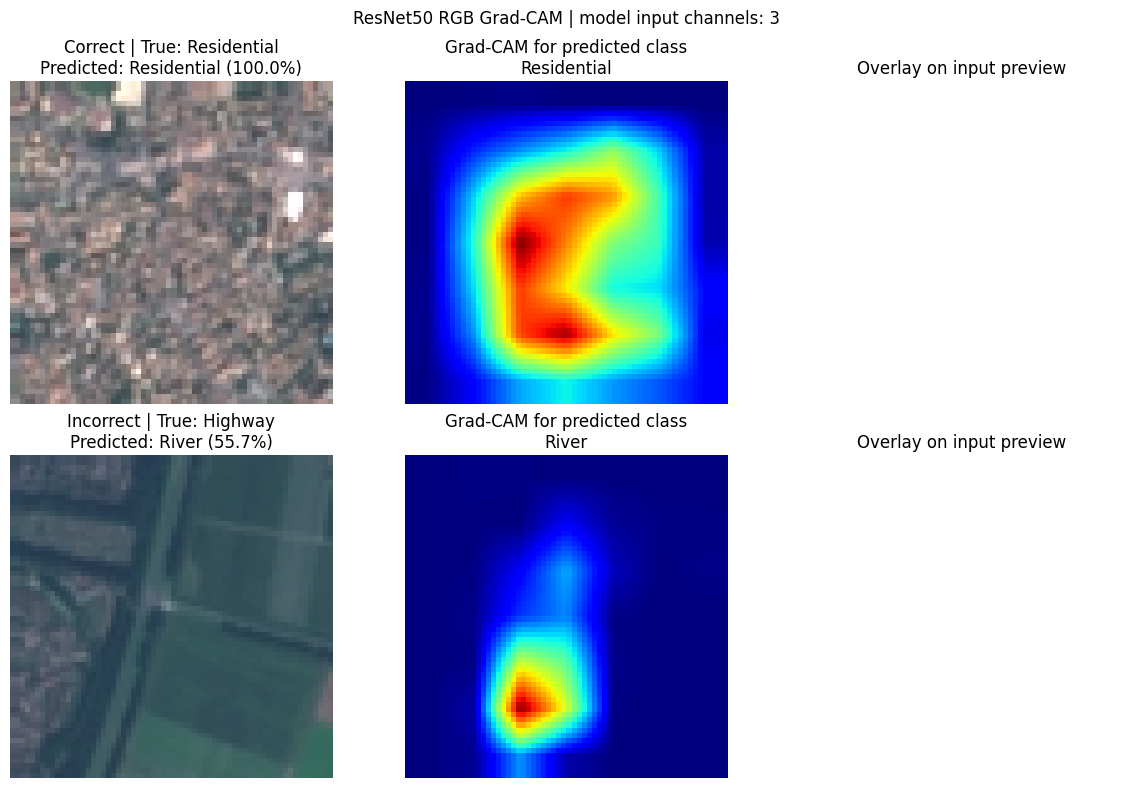

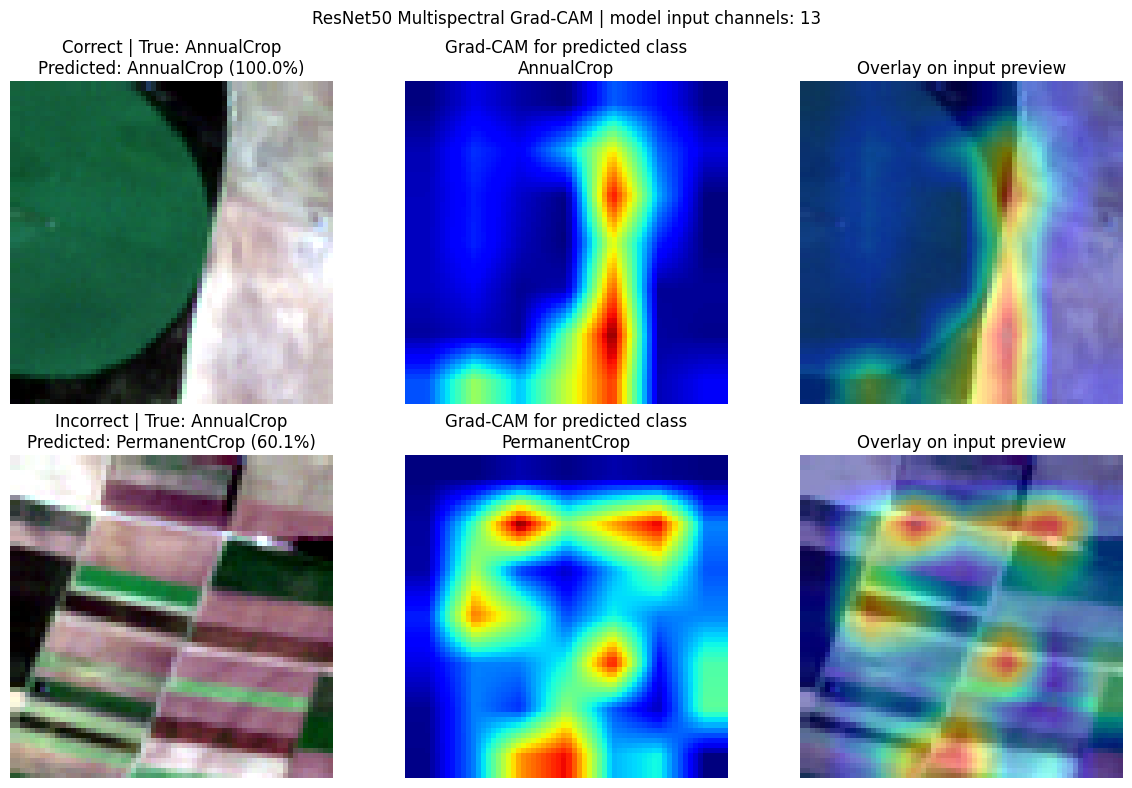

In [57]:
def _analysis_tensor_at_position(model_name, position):
    if model_name == "ResNet50 RGB":
        if "test_set" not in globals():
            raise RuntimeError("RGB test_set is unavailable.")
        return test_set[int(position)][0]
    if "MS_TEST_SET" not in globals():
        raise RuntimeError("MS_TEST_SET is unavailable.")
    return MS_TEST_SET[int(position)][0]

def _analysis_preview_at_position(model_name, position):
    if model_name == "ResNet50 RGB":
        return _rgb_test_preview(position)
    record_index = int(MS_TEST_SET.indices[int(position)])
    return _multispectral_true_color_preview(record_index)

for model_name, model_instance in ANALYSIS_MODELS.items():
    result = ERROR_ANALYSIS_RESULTS.get(model_name)
    if model_instance is None or result is None:
        print(f"{model_name}: Grad-CAM skipped because model or test predictions are unavailable.")
        continue

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    correct_positions = np.flatnonzero(y_true == y_pred)
    incorrect_positions = np.flatnonzero(y_true != y_pred)
    selected_examples = []
    if correct_positions.size:
        selected_examples.append(("Correct", int(correct_positions[0])))
    if incorrect_positions.size:
        selected_examples.append(("Incorrect", int(incorrect_positions[0])))
    if not selected_examples:
        print(f"{model_name}: test set is empty; no Grad-CAM examples to display.")
        continue

    expected_channels = 3 if model_name.endswith("RGB") else 13
    fig, axes = plt.subplots(
        len(selected_examples), 3,
        figsize=(12, 4 * len(selected_examples)),
        squeeze=False,
    )
    for row_index, (status, position) in enumerate(selected_examples):
        try:
            input_tensor = _analysis_tensor_at_position(model_name, position)
            if input_tensor.shape[0] != expected_channels:
                raise ValueError(
                    f"{model_name} test item has {input_tensor.shape[0]} channels; "
                    f"expected {expected_channels}."
                )
            preview = _analysis_preview_at_position(model_name, position)
            cam, predicted_index, confidence, cam_target = generate_analysis_gradcam(
                model_instance,
                input_tensor,
                expected_channels=expected_channels,
            )
            cam_tensor = torch.from_numpy(cam).float()[None, None]
            cam_for_preview = F.interpolate(
                cam_tensor,
                size=preview.shape[:2],
                mode="bilinear",
                align_corners=False,
            )[0, 0].numpy()
            colored_cam = plt.get_cmap("jet")(cam_for_preview)[..., :3]
            overlay = np.clip(0.55 * preview + 0.45 * colored_cam, 0, 1)

            true_index = int(y_true[position])
            axes[row_index, 0].imshow(preview)
            axes[row_index, 0].set_title(
                f"{status} | True: {ANALYSIS_CLASS_NAMES[true_index]}\n"
                f"Predicted: {ANALYSIS_CLASS_NAMES[predicted_index]} ({confidence:.1%})"
            )
            axes[row_index, 1].imshow(cam_for_preview, cmap="jet", vmin=0, vmax=1)
            axes[row_index, 1].set_title(
                f"Grad-CAM for predicted class\n{ANALYSIS_CLASS_NAMES[cam_target]}"
            )
            axes[row_index, 2].imshow(overlay)
            axes[row_index, 2].set_title("Overlay on input preview")
            for axis in axes[row_index]:
                axis.axis("off")
        except Exception as error:
            for axis in axes[row_index]:
                axis.axis("off")
            axes[row_index, 0].text(
                0.02, 0.5,
                f"{status} example unavailable:\n{type(error).__name__}: {error}",
                transform=axes[row_index, 0].transAxes,
                wrap=True,
            )

    fig.suptitle(
        f"{model_name} Grad-CAM | model input channels: {expected_channels}"
    )
    plt.tight_layout()
    plt.show()


## Deployment Contract — Independent Checkpoint-Based Inference for the Future Online App

This section is the **backend reference** for the planned Gradio/Hugging Face Space. The future `app.py` must do the same steps **without loading training datasets or running this notebook**: (1) load one saved checkpoint on CPU, (2) instantiate the architecture with `weights=None` (no network download), (3) apply the checkpoint's own preprocessing, and (4) return class name, softmax model score, and top-3 scores.

- **RGB PNG/JPG:** ResNet50 or EfficientNet-B0 with 3 channels. Automatic RGB conversion and checkpoint-specific image-size/mean/std.
- **Multispectral GeoTIFF:** ResNet50 with **13 exact bands**; use the stored `band_order`, mean, std, valid-mask handling, and bilinear resizing. Reject 3-band images or incompatible/partially identified band descriptions.
- Softmax is an **uncalibrated model score**; never promise correctness on unrelated imagery. The app must validate file type, image readability, and 13-band shape/order for multispectral inputs.

The CPU smoke tests in the next cell call these checkpoint-only functions after the weights are retrieved **from the persistent Drive folder**, not the in-memory trained models.

In [58]:
# These functions intentionally rely only on the checkpoint, torch/torchvision,
# PIL, numpy and (for TIFF files) Rasterio. They do NOT need trained globals.
def load_deployment_model(checkpoint_path, map_device="cpu"):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Deployment checkpoint not found: {checkpoint_path}")
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    required = {"model_state_dict", "class_names", "architecture", "input_channels", "image_size"}
    missing = required - set(saved)
    if missing:
        raise ValueError(f"Checkpoint lacks deployment metadata: {sorted(missing)}")
    class_labels = list(saved["class_names"])
    if len(class_labels) != 10 or len(set(class_labels)) != 10:
        raise ValueError("Expected the ten ordered EuroSAT classes.")
    channels = int(saved["input_channels"])
    architecture = saved["architecture"]
    if architecture == "resnet50" and channels == 3:
        fresh_model = models.resnet50(weights=None)
        fresh_model.fc = nn.Linear(fresh_model.fc.in_features, len(class_labels))
    elif architecture == "efficientnet_b0" and channels == 3:
        fresh_model = models.efficientnet_b0(weights=None)
        fresh_model.classifier[1] = nn.Linear(
            fresh_model.classifier[1].in_features, len(class_labels)
        )
    elif architecture == "resnet50_multispectral" and channels == 13:
        fresh_model = models.resnet50(weights=None)
        old = fresh_model.conv1
        fresh_model.conv1 = nn.Conv2d(
            13, old.out_channels, kernel_size=old.kernel_size,
            stride=old.stride, padding=old.padding, bias=False
        )
        fresh_model.fc = nn.Linear(fresh_model.fc.in_features, len(class_labels))
        if (len(saved.get("band_order", [])) != 13 or
            len(saved.get("normalization_mean", [])) != 13 or
            len(saved.get("normalization_std", [])) != 13):
            raise ValueError("13-band checkpoint missing band-order/normalization metadata.")
    else:
        raise ValueError(f"Unsupported deployment model: {architecture}, channels={channels}")
    fresh_model.load_state_dict(saved["model_state_dict"], strict=True)
    fresh_model.to(torch.device(map_device)).eval()
    return fresh_model, saved

def deployment_rgb_tensor(image, saved):
    if int(saved["input_channels"]) != 3:
        raise ValueError("RGB preprocessing requires a 3-channel checkpoint.")
    if isinstance(image, (str, Path)):
        with Image.open(image) as source:
            pil_image = source.convert("RGB")
    elif isinstance(image, Image.Image):
        pil_image = image.convert("RGB")
    else:
        raise TypeError("Use a Pillow image or a local image path.")
    pipeline = transforms.Compose([
        transforms.Resize((int(saved["image_size"]), int(saved["image_size"]))),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=list(saved["imagenet_mean"]),
            std=list(saved["imagenet_std"]),
        ),
    ])
    return pipeline(pil_image).unsqueeze(0)

def deployment_ms_tensor(tiff_path, saved):
    if int(saved["input_channels"]) != 13:
        raise ValueError("13-band TIFF preprocessing requires an MS checkpoint.")
    import rasterio
    import re
    with rasterio.open(tiff_path) as src:
        if src.count != 13:
            raise ValueError(f"Expected 13-band GeoTIFF, received {src.count} bands.")
        band_order = list(saved["band_order"])
        data = src.read(out_dtype="float32")
        masks = src.read_masks()
        nodata_values = list(src.nodatavals)
        descriptions = list(src.descriptions)
    def named_band(description):
        if not description:
            return None
        match = re.search(r"B(?:0[1-9]|1[0-2]|8A)", str(description).upper())
        return match.group(0) if match else None
    described = [named_band(item) for item in descriptions]
    if all(described):
        if len(set(described)) != 13 or set(described) != set(band_order):
            raise ValueError("GeoTIFF band descriptions do not match checkpoint band order.")
        indices = [described.index(name) for name in band_order]
        data = data[indices]
        masks = masks[indices]
        nodata_values = [nodata_values[idx] for idx in indices]
    elif any(described):
        raise ValueError("Incomplete GeoTIFF band descriptions: cannot verify band order.")
    # Without descriptions, only use TIFFs whose order is independently known to
    # match this EuroSAT checkpoint. Do not feed arbitrary external Sentinel-2 TIFFs.
    mean = np.asarray(saved["normalization_mean"], dtype=np.float32)[:, None, None]
    std = np.asarray(saved["normalization_std"], dtype=np.float32)[:, None, None]
    if not np.all(np.isfinite(std)) or np.any(std <= 0):
        raise ValueError("Invalid per-band normalization standard deviations.")
    valid = np.isfinite(data) & (masks > 0)
    for band_index, nodata in enumerate(nodata_values):
        if nodata is not None and np.isfinite(nodata):
            valid[band_index] &= data[band_index] != nodata
    valid &= ~np.all(data == 0, axis=0)[None, :, :]
    safe_data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)
    safe_data[~valid] = np.broadcast_to(mean, safe_data.shape)[~valid]
    normalized = (safe_data - mean) / std
    normalized[~valid] = 0.0
    image = torch.from_numpy(np.ascontiguousarray(normalized, dtype=np.float32)).unsqueeze(0)
    return torch.nn.functional.interpolate(
        image, size=(int(saved["image_size"]), int(saved["image_size"])),
        mode="bilinear", align_corners=False
    )

def deployment_predict(model, saved, input_tensor, top_k=3):
    expected_channels = int(saved["input_channels"])
    if input_tensor.ndim != 4 or input_tensor.shape[0] != 1 or input_tensor.shape[1] != expected_channels:
        raise ValueError(f"Expected batch (1, {expected_channels}, H, W), got {tuple(input_tensor.shape)}")
    parameter = next(model.parameters())
    with torch.inference_mode():
        logits = model(input_tensor.to(parameter.device))
        probabilities = torch.softmax(logits, dim=1)[0].cpu()
    if not torch.isfinite(probabilities).all():
        raise ValueError("Inference produced a non-finite score.")
    values, indices = torch.topk(probabilities, k=min(int(top_k), len(saved["class_names"])))
    items = [
        {"class_name": saved["class_names"][int(index)], "score": float(score)}
        for score, index in zip(values.tolist(), indices.tolist())
    ]
    return {"prediction": items[0]["class_name"], "model_score": items[0]["score"], "top3": items}

print("Checkpoint-only deployment functions ready (no training required to reuse them).")

Checkpoint-only deployment functions ready (no training required to reuse them).


## Deployment Smoke Tests — Fresh Models Reloaded from Persistent Checkpoints

Reload **each of the three models from Google Drive** on CPU with `weights=None`, validate checkpoint metadata, compare inference to the in-memory trained model on fixed held-out samples, and check that the original 13-band dataset preprocessing matches the independent TIFF preprocessing exactly. This tests the backend contract required for the planned online site.

In [59]:
DEPLOYMENT_SMOKE_RESULTS = []
PERSISTENT_MODEL_PATHS = {
    "ResNet50 RGB": RGB_PERSISTENT_CHECKPOINT_PATH,
    "EfficientNet-B0 RGB": EFFICIENTNET_PERSISTENT_CHECKPOINT_PATH,
    "ResNet50 Multispectral": MS_PERSISTENT_CHECKPOINT_PATH,
}

for label, original_model in [
    ("ResNet50 RGB", loaded_model),
    ("EfficientNet-B0 RGB", efficientnet_model),
    ("ResNet50 Multispectral", MS_MODEL),
]:
    deployed_model, deployed_config = load_deployment_model(
        PERSISTENT_MODEL_PATHS[label], map_device="cpu"
    )
    assert deployed_config["class_names"] == list(class_names)
    for fixed_position in (0, 10):
        if int(deployed_config["input_channels"]) == 3:
            original_index = int(test_set.indices[fixed_position])
            pil_image, original_label = dataset[original_index]
            reprocessed = deployment_rgb_tensor(pil_image, deployed_config)
            reference_input, test_label = test_set[fixed_position]
            assert int(test_label) == int(original_label)
        else:
            reference_input, test_label = MS_TEST_SET[fixed_position]
            tiff_index = int(MS_TEST_INDICES[fixed_position])
            tiff_path = MS_RECORDS[tiff_index]["path"]
            reprocessed = deployment_ms_tensor(tiff_path, deployed_config)
        assert tuple(reprocessed.shape) == (1, int(deployed_config["input_channels"]), int(deployed_config["image_size"]), int(deployed_config["image_size"]))
        assert torch.allclose(reprocessed.cpu(), reference_input.unsqueeze(0).cpu(), atol=1e-5, rtol=1e-5), (
            f"Input preprocessing mismatch for {label}"
        )
        prediction = deployment_predict(deployed_model, deployed_config, reprocessed)
        with torch.inference_mode():
            model_device = next(original_model.parameters()).device
            original_probabilities = torch.softmax(
                original_model(reference_input.unsqueeze(0).to(model_device)), dim=1
            )[0].cpu()
        reloaded_probabilities = torch.softmax(
            deployed_model(reprocessed), dim=1
        )[0].detach().cpu()
        max_probability_diff = float((original_probabilities - reloaded_probabilities).abs().max())
        assert max_probability_diff < 0.01, (
            f"Saved/restored weights disagree for {label}: max diff={max_probability_diff:.4g}"
        )
        assert prediction["prediction"] == deployed_config["class_names"][int(original_probabilities.argmax())]
        assert len(prediction["top3"]) == 3
        DEPLOYMENT_SMOKE_RESULTS.append({
            "Model": label,
            "Test position": fixed_position,
            "Predicted": prediction["prediction"],
            "True": class_names[int(test_label)],
            "Model score": prediction["model_score"],
            "Max CPU/GPU probability diff": max_probability_diff,
            "Checkpoint SHA256": sha256_file(PERSISTENT_MODEL_PATHS[label]),
            "Status": "PASS",
        })
    del deployed_model

# A 3-band upload must not be accepted by the 13-band model's input validator.
ms_model_for_validation, ms_config_for_validation = load_deployment_model(
    MS_PERSISTENT_CHECKPOINT_PATH, map_device="cpu"
)
try:
    deployment_predict(ms_model_for_validation, ms_config_for_validation, torch.zeros(1, 3, 224, 224))
except ValueError:
    print("PASS: multispectral model rejects RGB-only input.")
else:
    raise AssertionError("Multispectral input validation did not reject 3-channel input.")
del ms_model_for_validation

assert len(DEPLOYMENT_SMOKE_RESULTS) == 6
assert all(item["Status"] == "PASS" for item in DEPLOYMENT_SMOKE_RESULTS)
display(pd.DataFrame(DEPLOYMENT_SMOKE_RESULTS)[
    ["Model", "Test position", "True", "Predicted", "Model score", "Max CPU/GPU probability diff", "Status"]
])
print("PASSED: all three persisted models load and predict independently on CPU.")

PASS: multispectral model rejects RGB-only input.


,Model,Test position,True,Predicted,Model score,Max CPU/GPU probability diff,Status
0,ResNet50 RGB,0,Residential,Residential,0.999924,2.384186e-07,PASS
1,ResNet50 RGB,10,AnnualCrop,AnnualCrop,0.999930,1.192093e-07,PASS
2,EfficientNet-B0 RGB,0,Residential,Residential,0.998651,1.192093e-07,PASS
3,EfficientNet-B0 RGB,10,AnnualCrop,AnnualCrop,0.999453,2.384186e-07,PASS
4,ResNet50 Multispectral,0,AnnualCrop,AnnualCrop,0.999887,1.527951e-10,PASS
5,ResNet50 Multispectral,10,AnnualCrop,AnnualCrop,0.999209,1.192093e-07,PASS


PASSED: all three persisted models load and predict independently on CPU.


## 38. Optional Local Gradio Preview — **online website comes later**

The checkpoint-only deployment functions and persistent storage have already been tested above. The future **online** website will be a separate `app.py` + `requirements.txt` using **these exact inference functions**, deployed to a suitable host. This cell is only an **optional temporary Colab preview**; `LAUNCH_GRADIO_DEMO = False` by default. It does not require Gradio to be installed for a clean Run All.


In [60]:
# Do not launch a server or install packages during the final clean Run All.
LAUNCH_GRADIO_DEMO = False
if LAUNCH_GRADIO_DEMO:
    import gradio as gr
    rgb_checkpoint_path = RGB_PERSISTENT_CHECKPOINT_PATH
    deployment_model, deployment_config = load_deployment_model(
        rgb_checkpoint_path, map_device="cpu"
    )

    def predict_for_gradio(pil_image):
        if pil_image is None:
            return "Please upload a satellite RGB image.", {}
        tensor = deployment_rgb_tensor(pil_image, deployment_config)
        prediction = deployment_predict(deployment_model, deployment_config, tensor)
        top_scores = {entry["class_name"]: entry["score"] for entry in prediction["top3"]}
        return f"{prediction['prediction']} — model score: {prediction['model_score']:.1%}", top_scores

    with gr.Blocks(title="EuroSAT Land Cover Classifier") as demo:
        gr.Markdown("# EuroSAT Land Cover Classifier\nUpload a satellite RGB image (JPG/PNG).")
        image_input = gr.Image(type="pil", label="Satellite image")
        predict_button = gr.Button("Classify image")
        prediction_text = gr.Textbox(label="Predicted land type")
        top_three = gr.Label(label="Top 3 model scores", num_top_classes=3)
        predict_button.click(predict_for_gradio, inputs=image_input, outputs=[prediction_text, top_three])
    demo.launch(share=False)
else:
    print("Online deployment backend verified; optional Gradio preview disabled for Run All.")


Online deployment backend verified; optional Gradio preview disabled for Run All.


## 39. Final Project Documentation — Methodology and Limitations

**Task.** Ten-class EuroSAT land-cover classification using pretrained ResNet50 RGB, EfficientNet-B0 RGB, and ResNet50 multispectral (13 bands).

**Dataset and splits.** EuroSAT has 27,000 labeled 64×64 patches, separated into 18,900 train / 4,050 validation / 4,050 test (stratified; random seed 42). RGB JPEGs and multispectral TIFFs must match by class/name and use exactly the same split. Training-time augmentation never applies to validation or test.

**Preprocessing.** RGB: resized to 224×224 and ImageNet normalized. MS: training-only per-band normalization, validity masking, bilinear resizing to 224×224, and original 13-channel order. A 224×224 resize does not create new physical spatial detail.

**Evaluation.** Validation loss selects the best model epoch. Held-out test results are reported once per final run with accuracy, macro precision, macro recall, macro F1, class reports and confusion matrices. Final numeric results are printed and exported in the last cells; **do not copy historical figures from prior runs**. Training duration is recorded from the current execution.

**Deployment preparation.** All three checkpoints are saved locally and backed up to a versioned Google Drive directory. Checkpoints include an architecture identifier, channel count, class mapping and normalization metadata. A clean CPU-only model reload, RGB and TIFF preprocessing parity, and inference smoke tests are run before exporting a deployment manifest for a future online Gradio app.

**Limitations.** An image-level split is not a geographic holdout. Test results do not establish accuracy on independent Egyptian scenes. Softmax output is a model score, **not a calibrated probability**. The 13-band model cannot accept ordinary PNG/JPEG input; band order and physical-value scaling of a new GeoTIFF must be verified before inference. No Desert class exists in the current 10 classes.

**References:** [EuroSAT paper](https://arxiv.org/abs/1709.00029), [EuroSAT data](https://zenodo.org/records/7711810), [Torchvision models](https://pytorch.org/vision/stable/models.html), [Grad-CAM](https://arxiv.org/abs/1610.02391), [Gradio](https://www.gradio.app/).


In [61]:
final_status = {
    "ResNet50 test accuracy": float(accuracy_score(all_labels, all_predictions)),
    "ResNet50 macro F1": float(baseline_report_dict["macro avg"]["f1-score"]),
    "EfficientNet trained": "efficientnet_test_accuracy" in globals(),
}
if final_status["EfficientNet trained"]:
    final_status["EfficientNet-B0 test accuracy"] = float(efficientnet_test_accuracy)
    final_status["EfficientNet-B0 macro F1"] = float(efficientnet_report_dict["macro avg"]["f1-score"])
else:
    final_status["EfficientNet-B0 test accuracy"] = "Run EfficientNet training and evaluation to populate."
display(pd.DataFrame([final_status]))

,ResNet50 test accuracy,ResNet50 macro F1,EfficientNet trained,EfficientNet-B0 test accuracy,EfficientNet-B0 macro F1
0,0.979012,0.978635,True,0.97037,0.969344


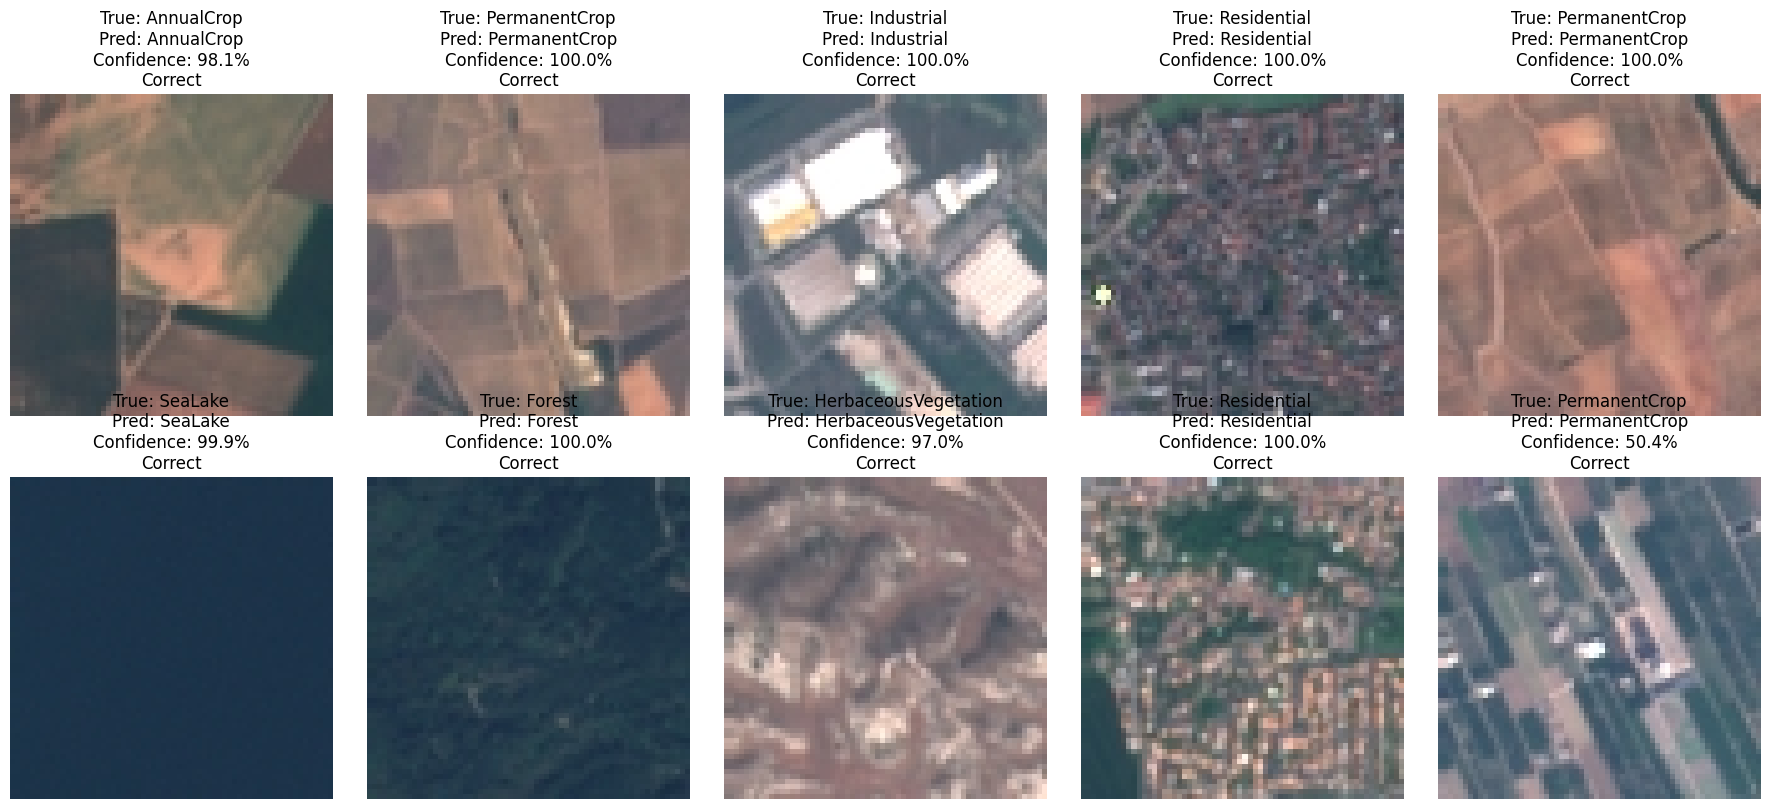

Correct Predictions: 10/10
Sample Accuracy: 100%


In [62]:
import random
import matplotlib.pyplot as plt
import torch

# Select 10 random images from the test dataset
random.seed(42)
sample_indices = random.sample(range(len(test_set)), 10)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

correct = 0

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    # Get original image
    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    # Predict
    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = loaded_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct Predictions: {correct}/10")
print(f"Sample Accuracy: {correct * 10}%")

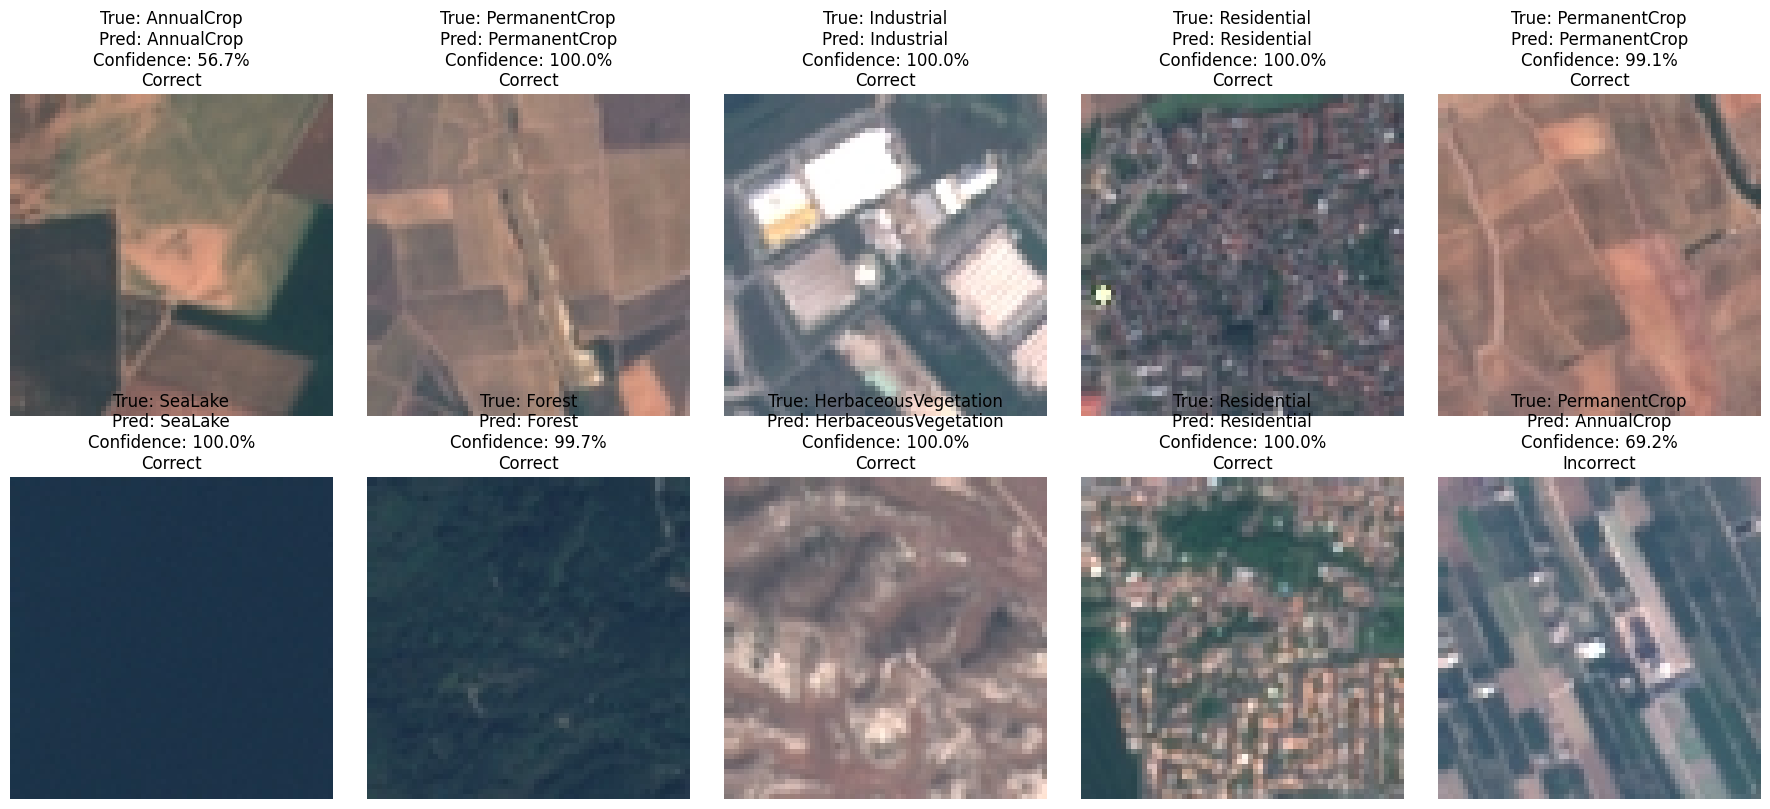

EfficientNet Correct: 9/10
EfficientNet Sample Accuracy: 90%


In [63]:
# Test EfficientNet-B0 on the same 10 images

efficientnet_model.eval()

correct = 0

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = efficientnet_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"EfficientNet Correct: {correct}/10")
print(f"EfficientNet Sample Accuracy: {correct * 10}%")

## Final Clean-Run Verification, Metrics Export, and Deployment Manifest

**Required after Restart & Run All:** the final cell checks the exact test split, all three **persistent** checkpoint hashes and metadata, successful independent CPU deployment tests, and machine-readable results. It exports `final_test_metrics.csv`, `deployment_manifest.json`, and `final_run_audit.json` into the same versioned Drive folder as the `.pth` files.

It **cannot prove that the runtime was restarted or that execution counts are sequential**: verify that manually in the saved notebook (all code cells executed exactly once in order; no errors), then save or download the executed `.ipynb`. The model outputs in this file must be generated by your **new run** before considering the project fully validated.


In [64]:
# Final audit: require all three real evaluations, matching splits, persisted checkpoints,
# and independent CPU inference tests. Fail loudly if any requirement is missing.
required_names = [
    "test_accuracy", "all_labels", "all_predictions", "MODEL_PATH",
    "efficientnet_test_accuracy", "efficientnet_test_labels",
    "efficientnet_test_predictions", "EFFICIENTNET_MODEL_PATH",
    "MS_TEST_METRICS", "MS_CHECKPOINT_PATH", "MS_TEST_LABELS",
    "MS_TEST_PREDICTIONS", "DEPLOYMENT_SMOKE_RESULTS",
]
missing_names = [name for name in required_names if name not in globals()]
assert not missing_names, f"Required earlier stages did not finish: {missing_names}"
assert (len(train_indices), len(val_indices), len(test_indices)) == (18_900, 4_050, 4_050)
assert (len(MS_TRAIN_INDICES), len(MS_VAL_INDICES), len(MS_TEST_INDICES)) == (18_900, 4_050, 4_050)
assert same_samples and same_labels, "RGB/MS image membership differs."
assert len(all_labels) == len(all_predictions) == 4050
assert len(efficientnet_test_labels) == len(efficientnet_test_predictions) == 4050
assert len(MS_TEST_LABELS) == len(MS_TEST_PREDICTIONS) == 4050
assert int(MS_TEST_METRICS["test_images"]) == 4050
assert np.array_equal(np.asarray(all_labels), np.asarray(efficientnet_test_labels))
# The TIFF loader enumerates class/filenames in a different order from RGB ImageFolder.
# Verify sample-key and true-label equality, NOT positional array equality.
rgb_test_keys = {
    (class_names[int(dataset.samples[int(idx)][1])], Path(dataset.samples[int(idx)][0]).stem)
    for idx in test_indices
}
ms_test_keys = {MS_KEYS[int(idx)] for idx in MS_TEST_INDICES}
assert rgb_test_keys == ms_test_keys, "RGB and multispectral test sets are not the same images."
assert all(
    int(MS_LABELS[ms_key_to_index[key]]) == int(dataset.samples[rgb_key_to_index[key]][1])
    for key in rgb_test_keys
), "RGB/MS test labels do not match by filename key."
assert all(item["Status"] == "PASS" for item in DEPLOYMENT_SMOKE_RESULTS)
assert len(DEPLOYMENT_SMOKE_RESULTS) == 6

from sklearn.metrics import precision_recall_fscore_support

def summarize_run_predictions(model_name, truth, predicted, training_seconds):
    accuracy = float(accuracy_score(truth, predicted))
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, predicted, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0
    )
    return {
        "Model": model_name,
        "Test images": int(len(truth)),
        "Test accuracy": accuracy,
        "Macro precision": float(precision),
        "Macro recall": float(recall),
        "Macro F1": float(f1),
        "Errors": int(np.count_nonzero(np.asarray(truth) != np.asarray(predicted))),
        "Training seconds": float(training_seconds),
    }

FINAL_METRICS_ROWS = [
    summarize_run_predictions("ResNet50 RGB", all_labels, all_predictions, RGB_TRAINING_SECONDS),
    summarize_run_predictions("EfficientNet-B0 RGB", efficientnet_test_labels, efficientnet_test_predictions, efficientnet_training_seconds),
    summarize_run_predictions("ResNet50 Multispectral", MS_TEST_LABELS, MS_TEST_PREDICTIONS, MS_TRAINING_SECONDS),
]
FINAL_TEST_METRICS = pd.DataFrame(FINAL_METRICS_ROWS)
display(FINAL_TEST_METRICS.round(4))

EXPECTED_ARCHS = {
    "ResNet50 RGB": ("resnet50", 3),
    "EfficientNet-B0 RGB": ("efficientnet_b0", 3),
    "ResNet50 Multispectral": ("resnet50_multispectral", 13),
}
CHECKPOINT_MANIFEST = {}
for label, path in PERSISTENT_MODEL_PATHS.items():
    assert path.is_file() and path.stat().st_size > 1_000_000, f"Missing/empty checkpoint: {path}"
    saved = torch.load(path, map_location="cpu", weights_only=True)
    expected_arch, expected_channels = EXPECTED_ARCHS[label]
    assert saved["architecture"] == expected_arch
    assert int(saved["input_channels"]) == expected_channels
    assert saved["class_names"] == list(class_names)
    assert saved["image_size"] == IMAGE_SIZE
    if expected_channels == 13:
        assert saved["band_order"] == EUROSAT_MS_BAND_ORDER
        assert len(saved["normalization_mean"]) == len(saved["normalization_std"]) == 13
    else:
        assert len(saved["imagenet_mean"]) == len(saved["imagenet_std"]) == 3
    local_path = {
        "ResNet50 RGB": MODEL_PATH,
        "EfficientNet-B0 RGB": EFFICIENTNET_MODEL_PATH,
        "ResNet50 Multispectral": MS_CHECKPOINT_PATH,
    }[label]
    assert sha256_file(path) == sha256_file(local_path)
    CHECKPOINT_MANIFEST[label] = {
        "filename": path.name,
        "architecture": expected_arch,
        "input_channels": expected_channels,
        "image_size": IMAGE_SIZE,
        "sha256": sha256_file(path),
        "size_mib": round(path.stat().st_size / 1024**2, 3),
        "best_epoch": int(saved["best_epoch"]),
        "class_names": list(saved["class_names"]),
    }

manifest = {
    "format_version": 1,
    "run_id": RUN_ID,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "EuroSAT",
    "seed": int(SEED),
    "split": {"train": 18900, "validation": 4050, "test": 4050},
    "test_split": "stratified, image-level; RGB and 13-band MS samples paired by filename/class",
    "classes": list(class_names),
    "models": CHECKPOINT_MANIFEST,
    "metrics": FINAL_METRICS_ROWS,
    "future_app": "RGB JPG/PNG supported by ResNet50 RGB and EfficientNet-B0; 13-band TIFF by ResNet50 MS",
    "limitations": ["Not a geographic holdout", "Softmax model scores are not calibrated", "External 13-band TIFF ordering and units must match the checkpoint"],
}

# Save the final reporting artifacts. JSON uses Python native scalars and excludes raw image data.
metrics_file = PERSISTENT_CHECKPOINT_DIR / "final_test_metrics.csv"
manifest_file = PERSISTENT_CHECKPOINT_DIR / "deployment_manifest.json"
audit_file = PERSISTENT_CHECKPOINT_DIR / "final_run_audit.json"
FINAL_TEST_METRICS.to_csv(metrics_file, index=False)
manifest_file.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
audit = {
    "run_id": RUN_ID,
    "evaluation": "PASSED",
    "test_samples_per_model": 4050,
    "paired_rgb_ms_test": True,
    "smoke_test_count": len(DEPLOYMENT_SMOKE_RESULTS),
    "checkpoint_hashes_verified": True,
    "manual_fresh_run_review_required": True,
    "runtime": {"torch": torch.__version__, "torchvision": torchvision.__version__},
}
audit_file.write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8")
for file_path in (metrics_file, manifest_file, audit_file):
    assert file_path.is_file() and file_path.stat().st_size > 0
print("PASSED: paired test splits, evaluation, all checkpoints, hashes, and independent inference tests.")
print("Persistent artifact folder:", PERSISTENT_CHECKPOINT_DIR)
print("Artifacts:")
for path in sorted(PERSISTENT_CHECKPOINT_DIR.iterdir()):
    print(f" - {path.name}: {path.stat().st_size / 1024**2:.2f} MiB")
print("MANUAL FINAL STEP: confirm fresh sequential execution, no error outputs, and save the executed notebook.")


,Model,Test images,Test accuracy,Macro precision,Macro recall,Macro F1,Errors,Training seconds
0,ResNet50 RGB,4050,0.9790,0.9785,0.9789,0.9786,85,746.4859
1,EfficientNet-B0 RGB,4050,0.9704,0.9690,0.9698,0.9693,120,956.0042
2,ResNet50 Multispectral,4050,0.9869,0.9863,0.9864,0.9863,53,5017.3211


PASSED: paired test splits, evaluation, all checkpoints, hashes, and independent inference tests.
Persistent artifact folder: /content/drive/MyDrive/Land_Type_Classification/checkpoints/run_20261121_003103_UTC
Artifacts:
 - best_efficientnet_b0_eurosat_two_blocks.pth: 15.62 MiB
 - best_resnet50_eurosat.pth: 90.05 MiB
 - best_resnet50_eurosat_multispectral.pth: 90.26 MiB
 - deployment_manifest.json: 0.00 MiB
 - final_run_audit.json: 0.00 MiB
 - final_test_metrics.csv: 0.00 MiB
MANUAL FINAL STEP: confirm fresh sequential execution, no error outputs, and save the executed notebook.
